In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

DATA_DIR = BASE_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
MODEL_DIR = BASE_DIR / "models"
REPORT_DIR = BASE_DIR / "reports"

print("Project directories configured.")
print("Base directory:", BASE_DIR)

Project directories configured.
Base directory: c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction


In [3]:
DATA_PATH = RAW_DATA_DIR / "hiring_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 11)


In [4]:
df.head()

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100)
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,NaN,AI Researcher,Hire,104895,8,100
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,Hire,113002,1,100
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,Hire,71766,7,70
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,Hire,46848,0,95
4,5,Julie Hill,"SQL, React, Java",4,PhD,NaN,Software Engineer,Hire,87441,9,100


In [5]:
df.tail()

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100)
995,996,Brenda Williams,"Cybersecurity, Linux, Ethical Hacking",0,B.Sc,NaN,Cybersecurity Analyst,Reject,114364,9,60
996,997,Colleen Hicks,"Deep Learning, Machine Learning",0,MBA,Deep Learning Specialization,Data Scientist,Reject,103294,5,45
997,998,Michelle Molina,"TensorFlow, NLP",0,B.Tech,Google ML,AI Researcher,Hire,113855,9,65
998,999,Danielle Horn,"Linux, Networking, Cybersecurity, Ethical Hacking",8,PhD,AWS Certified,Cybersecurity Analyst,Hire,83146,10,100
999,1000,Chad Collins,"SQL, Machine Learning, Python, Deep Learning",7,M.Tech,Deep Learning Specialization,Data Scientist,Hire,119474,3,100


In [6]:
df.sample(5)

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100)
579,580,John Wilson,"Deep Learning, SQL",1,B.Tech,AWS Certified,Data Scientist,Reject,50848,4,50
902,903,Lisa White,"Deep Learning, Machine Learning, SQL, Python",6,PhD,Deep Learning Specialization,Data Scientist,Hire,48306,10,100
612,613,Dennis Wheeler,"NLP, Pytorch",8,B.Sc,AWS Certified,AI Researcher,Hire,41624,4,100
42,43,Justin Ross,"NLP, TensorFlow, Python",3,M.Tech,NaN,AI Researcher,Hire,66403,10,95
623,624,Luke Johnson,"Pytorch, NLP",5,M.Tech,AWS Certified,AI Researcher,Hire,64489,4,90


In [7]:
print("Columns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")
    

Columns:
1. Resume_ID
2. Name
3. Skills
4. Experience (Years)
5. Education
6. Certifications
7. Job Role
8. Recruiter Decision
9. Salary Expectation ($)
10. Projects Count
11. AI Score (0-100)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Resume_ID               1000 non-null   int64
 1   Name                    1000 non-null   str  
 2   Skills                  1000 non-null   str  
 3   Experience (Years)      1000 non-null   int64
 4   Education               1000 non-null   str  
 5   Certifications          726 non-null    str  
 6   Job Role                1000 non-null   str  
 7   Recruiter Decision      1000 non-null   str  
 8   Salary Expectation ($)  1000 non-null   int64
 9   Projects Count          1000 non-null   int64
 10  AI Score (0-100)        1000 non-null   int64
dtypes: int64(5), str(6)
memory usage: 86.1 KB


In [9]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Resume_ID,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Name,1000,989,Sarah Jones,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Skills,1000,238,"SQL, Java",11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Experience (Years),1000.0,NaN,NaN,NaN,4.896,3.112695,0.0,2.0,5.0,8.0,10.0
Education,1000,5,B.Sc,205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Certifications,726,3,Deep Learning Specialization,255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job Role,1000,4,AI Researcher,257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Recruiter Decision,1000,2,Hire,812,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary Expectation ($),1000.0,NaN,NaN,NaN,79994.486,23048.472549,40085.0,60415.75,79834.5,99583.25,119901.0
Projects Count,1000.0,NaN,NaN,NaN,5.133,3.23137,0.0,2.0,5.0,8.0,10.0


In [10]:
missing = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
Certifications,274,27.4
Name,0,0.0
Resume_ID,0,0.0
Skills,0,0.0
Experience (Years),0,0.0
Education,0,0.0
Job Role,0,0.0
Recruiter Decision,0,0.0
Salary Expectation ($),0,0.0
Projects Count,0,0.0


In [11]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [12]:
if duplicate_count > 0:
    print("Duplicate records found.")
else:
    print("No duplicate records found.")

No duplicate records found.


In [13]:
print(df.columns.tolist())

['Resume_ID', 'Name', 'Skills', 'Experience (Years)', 'Education', 'Certifications', 'Job Role', 'Recruiter Decision', 'Salary Expectation ($)', 'Projects Count', 'AI Score (0-100)']


In [14]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd().parent
RAW_DATA_DIR = BASE_DIR / "data" / "raw"

print("Looking for CSV files in:")
print(RAW_DATA_DIR)

print("\nFiles found:")
for file in RAW_DATA_DIR.iterdir():
    print(file.name)

Looking for CSV files in:
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\raw

Files found:
hiring_dataset.csv


In [15]:
DATA_PATH = RAW_DATA_DIR / "hiring_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (1000, 11)

Columns:
['Resume_ID', 'Name', 'Skills', 'Experience (Years)', 'Education', 'Certifications', 'Job Role', 'Recruiter Decision', 'Salary Expectation ($)', 'Projects Count', 'AI Score (0-100)']


In [16]:
TARGET = "Recruiter Decision"

print("Target variable:", TARGET)

print("\nUnique values:")
print(df[TARGET].unique())

print("\nValue counts:")
print(df[TARGET].value_counts())

print("\nPercentage distribution:")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target variable: Recruiter Decision

Unique values:
<StringArray>
['Hire', 'Reject']
Length: 2, dtype: str

Value counts:
Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: int64

Percentage distribution:
Recruiter Decision
Hire      81.2
Reject    18.8
Name: proportion, dtype: float64


In [17]:
print(df.dtypes)

Resume_ID                 int64
Name                        str
Skills                      str
Experience (Years)        int64
Education                   str
Certifications              str
Job Role                    str
Recruiter Decision          str
Salary Expectation ($)    int64
Projects Count            int64
AI Score (0-100)          int64
dtype: object


In [18]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2),
    "Data Type": df.dtypes
})

missing_report.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing %,Data Type
Certifications,274,27.4,str
Name,0,0.0,str
Resume_ID,0,0.0,int64
Skills,0,0.0,str
Experience (Years),0,0.0,int64
Education,0,0.0,str
Job Role,0,0.0,str
Recruiter Decision,0,0.0,str
Salary Expectation ($),0,0.0,int64
Projects Count,0,0.0,int64


In [19]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

print("\nDuplicate Resume IDs:", df["Resume_ID"].duplicated().sum())

Total rows: 1000
Duplicate rows: 0

Duplicate Resume IDs: 0


In [20]:
categorical_columns = [
    "Education",
    "Certifications",
    "Job Role",
    "Recruiter Decision"
]

for column in categorical_columns:
    print("\n" + "=" * 50)
    print(column)
    print("=" * 50)
    print(df[column].value_counts(dropna=False))


Education
Education
B.Sc      205
MBA       202
B.Tech    200
M.Tech    198
PhD       195
Name: count, dtype: int64

Certifications
Certifications
NaN                             274
Deep Learning Specialization    255
AWS Certified                   249
Google ML                       222
Name: count, dtype: int64

Job Role
Job Role
AI Researcher            257
Data Scientist           255
Cybersecurity Analyst    255
Software Engineer        233
Name: count, dtype: int64

Recruiter Decision
Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: int64


In [21]:
numerical_columns = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "AI Score (0-100)"
]

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Experience (Years),1000.0,4.896,3.112695,0.0,2.00,5.0,8.00,10.0
Salary Expectation ($),1000.0,79994.486,23048.472549,40085.0,60415.75,79834.5,99583.25,119901.0
Projects Count,1000.0,5.133,3.231370,0.0,2.00,5.0,8.00,10.0
AI Score (0-100),1000.0,83.950,20.983036,15.0,70.00,100.0,100.00,100.0


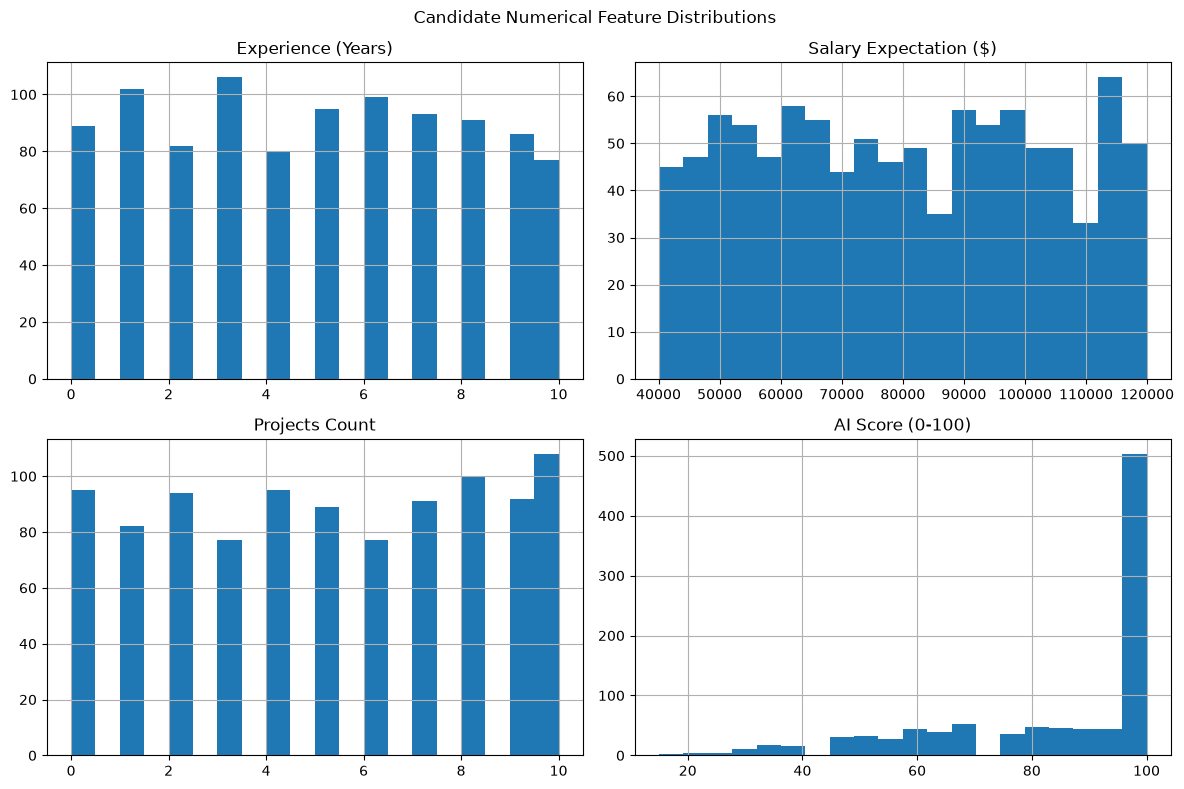

In [22]:
df[numerical_columns].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle("Candidate Numerical Feature Distributions")
plt.tight_layout()
plt.show()

In [23]:
print(df["Skills"].head(20).to_string(index=False))
print("\nNumber of unique skill strings:")
print(df["Skills"].nunique())

                         TensorFlow, NLP, Pytorch
     Deep Learning, Machine Learning, Python, SQL
            Ethical Hacking, Cybersecurity, Linux
                      Python, Pytorch, TensorFlow
                                 SQL, React, Java
Cybersecurity, Networking, Linux, Ethical Hacking
       Networking, Cybersecurity, Ethical Hacking
                         TensorFlow, Pytorch, NLP
                      Networking, Ethical Hacking
                 Python, TensorFlow, Pytorch, NLP
                                   SQL, Java, C++
       Cybersecurity, Ethical Hacking, Networking
                        Cybersecurity, Networking
                                   SQL, C++, Java
                                     Pytorch, NLP
                        Cybersecurity, Networking
                                      SQL, Python
Linux, Networking, Cybersecurity, Ethical Hacking
                       SQL, Python, Deep Learning
                    Machine Learning, SQL, Python


In [24]:
print(df["Certifications"].head(20).to_string(index=False))
print("\nUnique certification combinations:")
print(df["Certifications"].nunique())

                         NaN
                   Google ML
Deep Learning Specialization
               AWS Certified
                         NaN
                   Google ML
               AWS Certified
               AWS Certified
Deep Learning Specialization
               AWS Certified
Deep Learning Specialization
                   Google ML
Deep Learning Specialization
Deep Learning Specialization
Deep Learning Specialization
                   Google ML
                         NaN
                         NaN
                         NaN
Deep Learning Specialization

Unique certification combinations:
3


In [25]:
for column in numerical_columns:
    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)

    print(
        df.groupby(TARGET)[column]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )


Experience (Years)
                    count  mean  median  min  max
Recruiter Decision                               
Hire                  812  5.76     6.0    0   10
Reject                188  1.17     1.0    0    4

Salary Expectation ($)
                    count      mean   median    min     max
Recruiter Decision                                         
Hire                  812  80483.02  80325.5  40162  119901
Reject                188  77884.41  76392.0  40085  118976

Projects Count
                    count  mean  median  min  max
Recruiter Decision                               
Hire                  812  5.65     6.0    0   10
Reject                188  2.91     3.0    0    9

AI Score (0-100)
                    count   mean  median  min  max
Recruiter Decision                                
Hire                  812  92.43   100.0   65  100
Reject                188  47.31    50.0   15   60


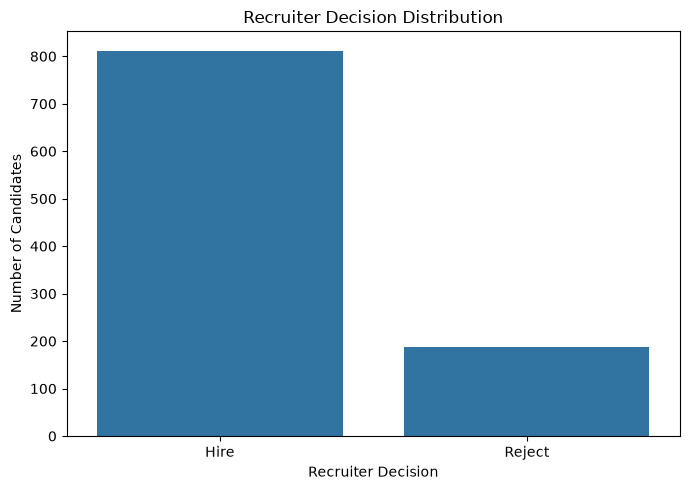

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET
)

plt.title("Recruiter Decision Distribution")
plt.xlabel("Recruiter Decision")
plt.ylabel("Number of Candidates")

plt.tight_layout()
plt.show()

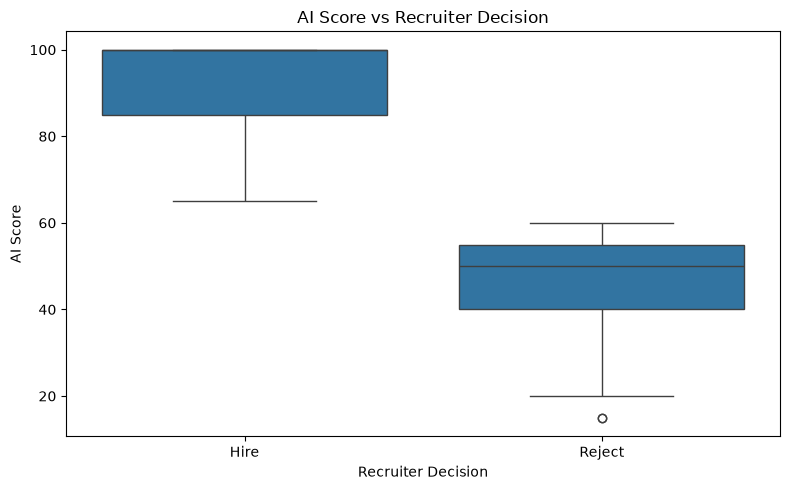

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x=TARGET,
    y="AI Score (0-100)"
)

plt.title("AI Score vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("AI Score")

plt.tight_layout()
plt.show()

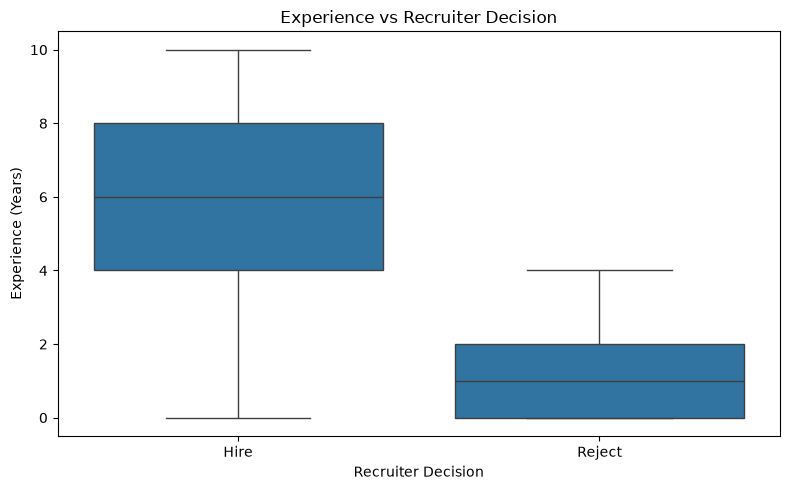

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x=TARGET,
    y="Experience (Years)"
)

plt.title("Experience vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("Experience (Years)")

plt.tight_layout()
plt.show()

In [29]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working shape:", df_clean.shape)

Original shape: (1000, 11)
Working shape: (1000, 11)


In [30]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df_clean.shape)


Duplicate rows found: 0
Shape after duplicate removal: (1000, 11)


In [31]:
duplicate_ids = df_clean["Resume_ID"].duplicated().sum()

print("Duplicate Resume IDs:", duplicate_ids)

Duplicate Resume IDs: 0


In [32]:
text_columns = [
    "Name",
    "Skills",
    "Education",
    "Certifications",
    "Job Role",
    "Recruiter Decision"
]

In [33]:
for column in text_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

print("Text columns cleaned.")

Text columns cleaned.


In [34]:
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing %": (df_clean.isnull().mean() * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values(
    "Missing Count",
    ascending=False
)

missing_report

,Missing Count,Missing %
Certifications,274,27.4


In [35]:
numerical_columns = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "AI Score (0-100)"
]

for column in numerical_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

print(df_clean[numerical_columns].dtypes)

Experience (Years)        int64
Salary Expectation ($)    int64
Projects Count            int64
AI Score (0-100)          int64
dtype: object


In [36]:
print("Experience < 0:")
print((df_clean["Experience (Years)"] < 0).sum())

print("\nProjects < 0:")
print((df_clean["Projects Count"] < 0).sum())

print("\nSalary < 0:")
print((df_clean["Salary Expectation ($)"] < 0).sum())

print("\nAI Score outside 0-100:")
print(
    (
        (df_clean["AI Score (0-100)"] < 0) |
        (df_clean["AI Score (0-100)"] > 100)
    ).sum()
)

Experience < 0:
0

Projects < 0:
0

Salary < 0:
0

AI Score outside 0-100:
0


In [37]:
df_clean["Experience_Level"] = pd.cut(
    df_clean["Experience (Years)"],
    bins=[-1, 1, 3, 5, 10, np.inf],
    labels=[
        "Fresher",
        "Junior",
        "Mid-Level",
        "Senior",
        "Expert"
    ]
)

df_clean[[
    "Experience (Years)",
    "Experience_Level"
]].head(10)

,Experience (Years),Experience_Level
0,10,Senior
1,10,Senior
2,1,Fresher
3,7,Senior
4,4,Mid-Level
5,10,Senior
6,4,Mid-Level
7,3,Junior
8,7,Senior
9,0,Fresher


In [38]:
def count_skills(value):
    if pd.isna(value) or str(value).strip() == "":
        return 0
    
    value = str(value)
    
    for separator in [";", "|"]:
        value = value.replace(separator, ",")
    
    skills = [
        skill.strip()
        for skill in value.split(",")
        if skill.strip()
    ]
    
    return len(skills)

In [39]:
df_clean["Skill_Count"] = df_clean["Skills"].apply(count_skills)

df_clean[[
    "Skills",
    "Skill_Count"
]].head(10)

,Skills,Skill_Count
0,"TensorFlow, NLP, Pytorch",3
1,"Deep Learning, Machine Learning, Python, SQL",4
2,"Ethical Hacking, Cybersecurity, Linux",3
3,"Python, Pytorch, TensorFlow",3
4,"SQL, React, Java",3
5,"Cybersecurity, Networking, Linux, Ethical Hacking",4
6,"Networking, Cybersecurity, Ethical Hacking",3
7,"TensorFlow, Pytorch, NLP",3
8,"Networking, Ethical Hacking",2
9,"Python, TensorFlow, Pytorch, NLP",4


In [40]:
def count_certifications(value):
    if pd.isna(value) or str(value).strip() == "":
        return 0
    
    value = str(value)
    
    for separator in [";", "|"]:
        value = value.replace(separator, ",")
    
    certifications = [
        cert.strip()
        for cert in value.split(",")
        if cert.strip()
    ]
    
    return len(certifications)

In [41]:
df_clean["Certification_Count"] = (
    df_clean["Certifications"]
    .apply(count_certifications)
)

df_clean[[
    "Certifications",
    "Certification_Count"
]].head(10)

,Certifications,Certification_Count
0,<NA>,0
1,Google ML,1
2,Deep Learning Specialization,1
3,AWS Certified,1
4,<NA>,0
5,Google ML,1
6,AWS Certified,1
7,AWS Certified,1
8,Deep Learning Specialization,1
9,AWS Certified,1


In [42]:
df_clean["Project_Experience_Index"] = (
    df_clean["Projects Count"] *
    (1 + df_clean["Experience (Years)"])
)

df_clean[[
    "Experience (Years)",
    "Projects Count",
    "Project_Experience_Index"
]].head(10)

,Experience (Years),Projects Count,Project_Experience_Index
0,10,8,88
1,10,1,11
2,1,7,14
3,7,0,0
4,4,9,45
5,10,5,55
6,4,9,45
7,3,7,28
8,7,3,24
9,0,1,1


In [43]:
print("Recruiter Decision values:")
print(
    df_clean["Recruiter Decision"]
    .value_counts(dropna=False)
)
print("\nUnique values:")
print(
    df_clean["Recruiter Decision"]
    .unique()
)

Recruiter Decision values:
Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: Int64

Unique values:
<StringArray>
['Hire', 'Reject']
Length: 2, dtype: string


In [44]:
df_clean.groupby("Recruiter Decision")[
    "AI Score (0-100)"
].agg([
    "count",
    "mean",
    "median",
    "min",
    "max"
]).round(2)

,count,mean,median,min,max
Recruiter Decision,,,,,
Hire,812,92.43,100.0,65,100
Reject,188,47.31,50.0,15,60


In [45]:
from pathlib import Path

# Project paths
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

# Create processed-data directory
PROCESSED_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save cleaned dataset
clean_path = PROCESSED_DATA_DIR / "hiring_cleaned_stage1.csv"

df_clean.to_csv(
    clean_path,
    index=False
)

print("Saved cleaned dataset successfully!")
print("Location:", clean_path)
print("Shape:", df_clean.shape)

Saved cleaned dataset successfully!
Location: c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\hiring_cleaned_stage1.csv
Shape: (1000, 15)


In [46]:
print(df_clean["Recruiter Decision"].value_counts(dropna=False))

Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: Int64


In [47]:
print(df_clean["Recruiter Decision"].unique())

<StringArray>
['Hire', 'Reject']
Length: 2, dtype: string


In [48]:
df_clean[[
    "Experience (Years)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "AI Score (0-100)"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
Experience (Years),1000.0,4.896,3.112695,0.0,2.0,5.0,8.0,10.0
Projects Count,1000.0,5.133,3.231370,0.0,2.0,5.0,8.0,10.0
Skill_Count,1000.0,3.017,0.805829,2.0,2.0,3.0,4.0,4.0
Certification_Count,1000.0,0.726,0.446232,0.0,0.0,1.0,1.0,1.0
AI Score (0-100),1000.0,83.950,20.983036,15.0,70.0,100.0,100.0,100.0


In [49]:
print("Cleaned dataset shape:", df_clean.shape)
display(df_clean.head())

Cleaned dataset shape: (1000, 15)


,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100),Experience_Level,Skill_Count,Certification_Count,Project_Experience_Index
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,<NA>,AI Researcher,Hire,104895,8,100,Senior,3,0,88
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,Hire,113002,1,100,Senior,4,1,11
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,Hire,71766,7,70,Fresher,3,1,14
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,Hire,46848,0,95,Senior,3,1,0
4,5,Julie Hill,"SQL, React, Java",4,PhD,<NA>,Software Engineer,Hire,87441,9,100,Mid-Level,3,0,45


In [50]:
print("Columns:")
print(df_clean.columns.tolist())

Columns:
['Resume_ID', 'Name', 'Skills', 'Experience (Years)', 'Education', 'Certifications', 'Job Role', 'Recruiter Decision', 'Salary Expectation ($)', 'Projects Count', 'AI Score (0-100)', 'Experience_Level', 'Skill_Count', 'Certification_Count', 'Project_Experience_Index']


In [51]:
TARGET = "Recruiter Decision"

decision_counts = df_clean[TARGET].value_counts(dropna=False)

print("Recruiter Decision Distribution")
print("=" * 40)
print(decision_counts)

print("\nPercentage Distribution")
print("=" * 40)
print(
    df_clean[TARGET]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Recruiter Decision Distribution
Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: Int64

Percentage Distribution
Recruiter Decision
Hire      81.2
Reject    18.8
Name: proportion, dtype: Float64


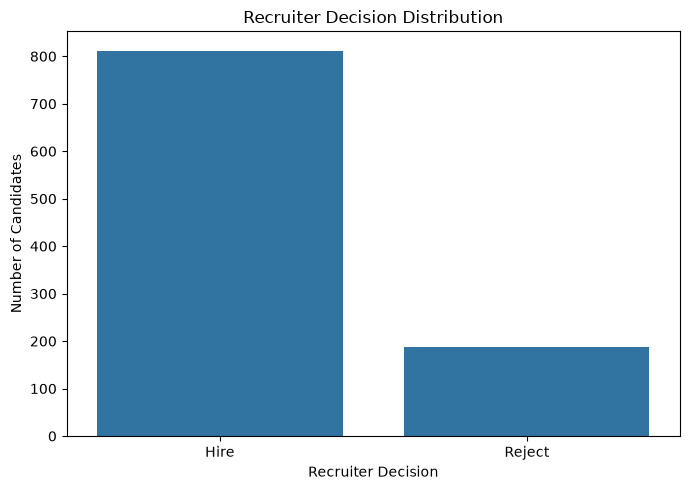

In [52]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x=TARGET
)

plt.title("Recruiter Decision Distribution")
plt.xlabel("Recruiter Decision")
plt.ylabel("Number of Candidates")

plt.tight_layout()
plt.show()

In [53]:
numerical_features = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "AI Score (0-100)",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index"
]

grouped_statistics = (
    df_clean
    .groupby(TARGET)[numerical_features]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(grouped_statistics)

Experience (Years)                             \
                                count  mean median   std min max   
Recruiter Decision                                                 
Hire                              812  5.76    6.0  2.77   0  10   
Reject                            188  1.17    1.0  1.14   0   4   

                   Salary Expectation ($)                               ...  \
                                    count      mean   median       std  ...   
Recruiter Decision                                                      ...   
Hire                                  812  80483.02  80325.5  22983.75  ...   
Reject                                188  77884.41  76392.0  23269.74  ...   

                   Certification_Count               Project_Experience_Index  \
                                median   std min max                    count   
Recruiter Decision                                                              
Hire                               1.0  0.44   0   1                      812   
Reject                             1.0  0.47   0   1                      188   

                                                  
                     mean median    std min  max  
Recruiter Decision                                
Hire                35.27   30.0  25.79   0  110  
Reject               5.07    5.0   3.70   0   16  

[2 rows x 42 columns]

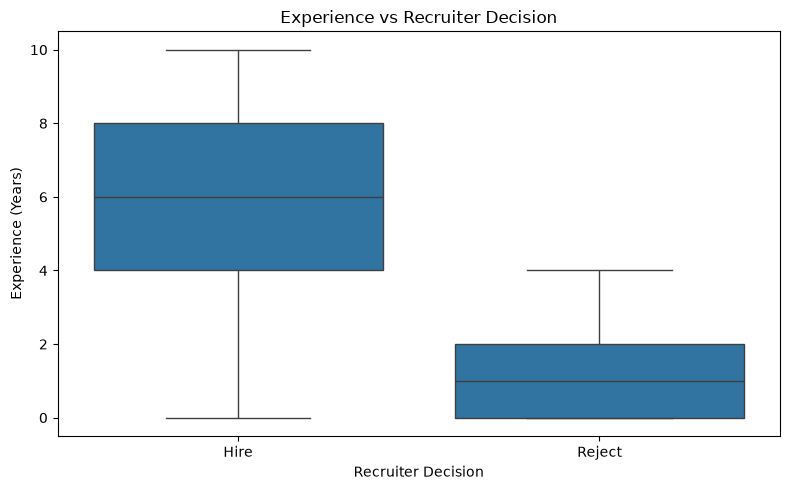

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x=TARGET,
    y="Experience (Years)"
)

plt.title("Experience vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("Experience (Years)")

plt.tight_layout()
plt.show()

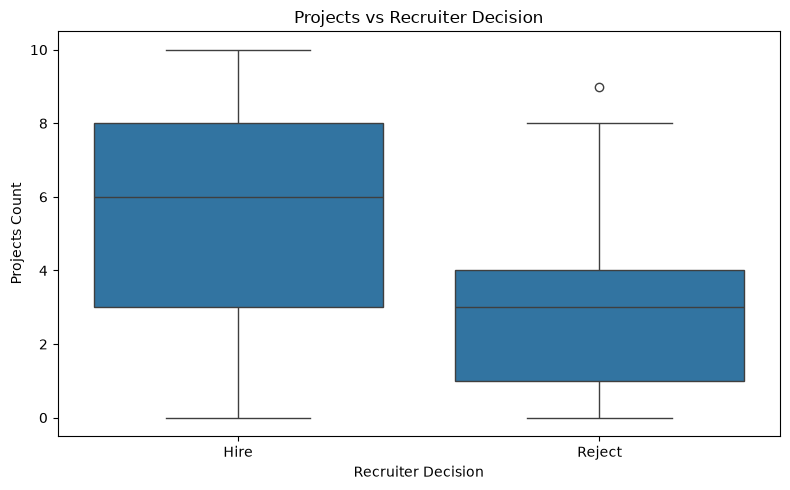

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x=TARGET,
    y="Projects Count"
)

plt.title("Projects vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("Projects Count")

plt.tight_layout()
plt.show()

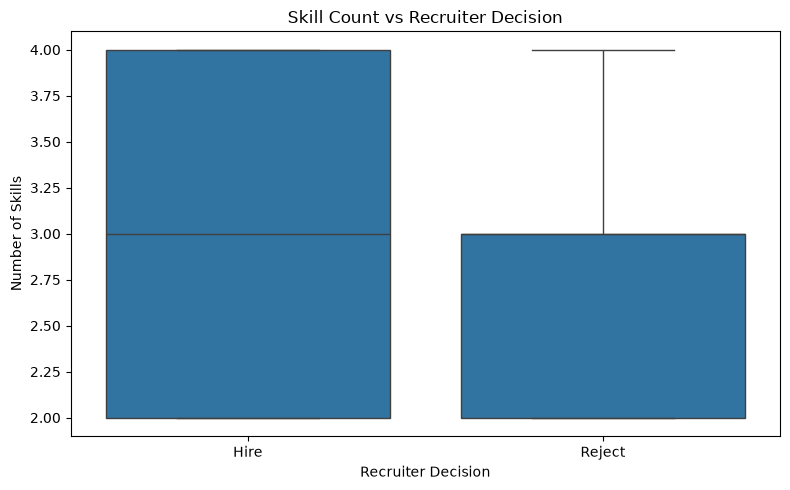

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x=TARGET,
    y="Skill_Count"
)

plt.title("Skill Count vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("Number of Skills")

plt.tight_layout()
plt.show()

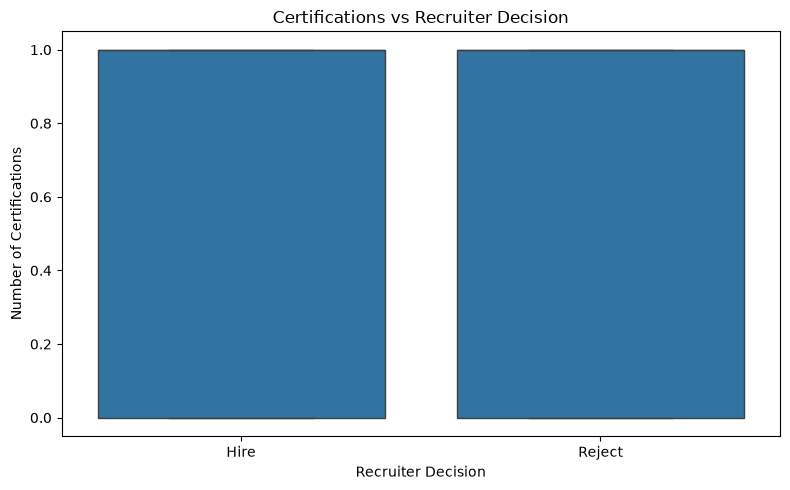

In [57]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x=TARGET,
    y="Certification_Count"
)

plt.title("Certifications vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("Number of Certifications")

plt.tight_layout()
plt.show()

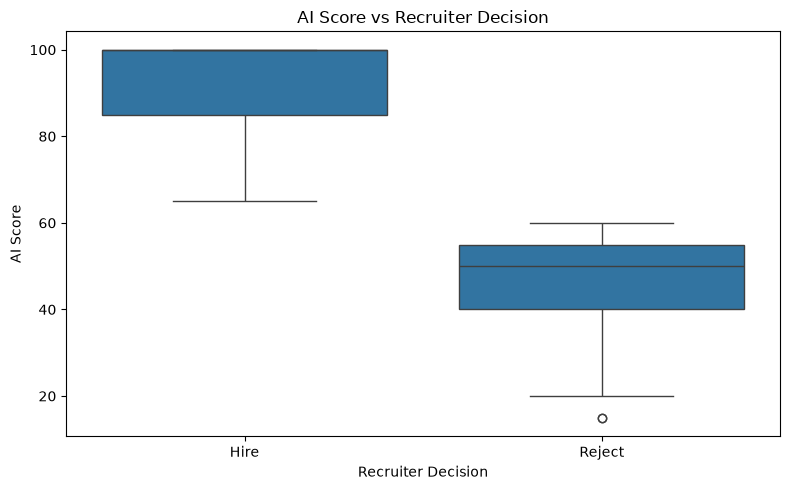

In [58]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x=TARGET,
    y="AI Score (0-100)"
)

plt.title("AI Score vs Recruiter Decision")
plt.xlabel("Recruiter Decision")
plt.ylabel("AI Score")

plt.tight_layout()
plt.show()

In [59]:
correlation_features = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "AI Score (0-100)",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index"
]

correlation_matrix = df_clean[correlation_features].corr()

display(correlation_matrix.round(2))

,Experience (Years),Salary Expectation ($),Projects Count,AI Score (0-100),Skill_Count,Certification_Count,Project_Experience_Index
Experience (Years),1.00,0.03,-0.07,0.78,0.04,0.00,0.55
Salary Expectation ($),0.03,1.00,0.02,0.03,0.03,0.00,0.04
Projects Count,-0.07,0.02,1.00,0.36,0.00,0.03,0.71
AI Score (0-100),0.78,0.03,0.36,1.00,0.12,0.11,0.62
Skill_Count,0.04,0.03,0.00,0.12,1.00,-0.04,0.04
Certification_Count,0.00,0.00,0.03,0.11,-0.04,1.00,0.03
Project_Experience_Index,0.55,0.04,0.71,0.62,0.04,0.03,1.00


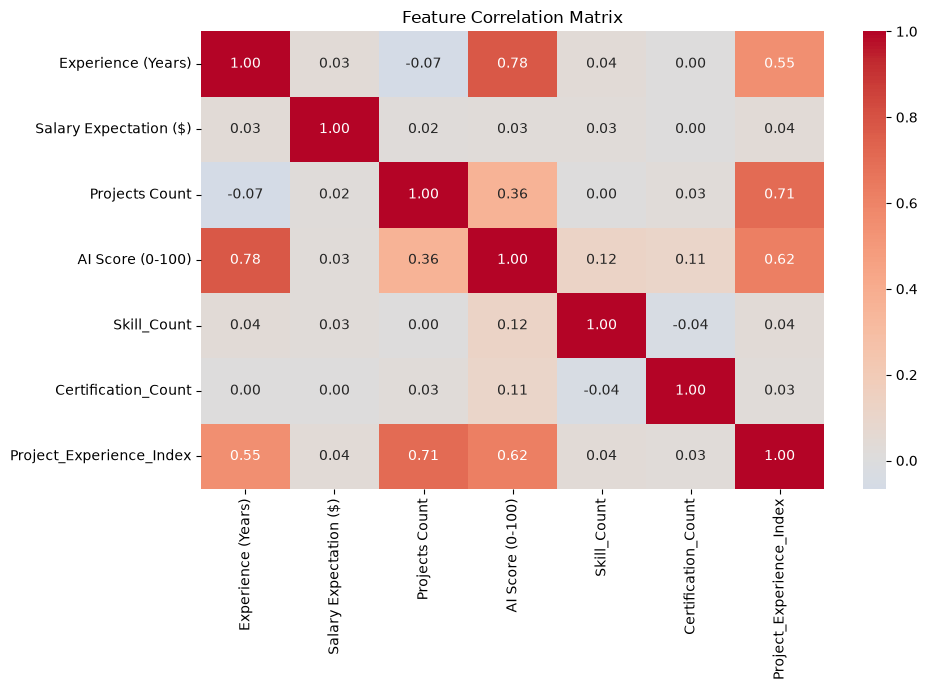

In [60]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [61]:
from scipy.stats import mannwhitneyu

In [62]:
print(df_clean[TARGET].value_counts())
print("\nNumber of unique decisions:", df_clean[TARGET].nunique())

Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: Int64

Number of unique decisions: 2


In [63]:
decision_values = df_clean[TARGET].dropna().unique()

group_1 = decision_values[0]
group_2 = decision_values[1]

print("Group 1:", group_1)
print("Group 2:", group_2)

Group 1: Hire
Group 2: Reject


In [64]:
statistical_results = []

for feature in numerical_features:
    
    group1_data = df_clean.loc[
        df_clean[TARGET] == group_1,
        feature
    ].dropna()
    
    group2_data = df_clean.loc[
        df_clean[TARGET] == group_2,
        feature
    ].dropna()
    
    statistic, p_value = mannwhitneyu(
        group1_data,
        group2_data,
        alternative="two-sided"
    )
    
    statistical_results.append({
        "Feature": feature,
        "U Statistic": statistic,
        "P Value": p_value
    })

statistical_results_df = pd.DataFrame(statistical_results)

statistical_results_df["Significant"] = (
    statistical_results_df["P Value"] < 0.05
)

statistical_results_df.sort_values("P Value")

,Feature,U Statistic,P Value,Significant
3,AI Score (0-100),152656.0,4.014434e-116,True
0,Experience (Years),141238.0,1.502971e-74,True
6,Project_Experience_Index,137305.5,1.491776e-65,True
2,Projects Count,113537.5,1.164616e-25,True
4,Skill_Count,85556.0,6.076282e-03,True
5,Certification_Count,81572.0,5.715800e-02,False
1,Salary Expectation ($),81399.5,1.553014e-01,False


In [65]:
job_role_analysis = pd.crosstab(
    df_clean["Job Role"],
    df_clean[TARGET]
)

display(job_role_analysis)

Recruiter Decision,Hire,Reject
Job Role,,
AI Researcher,210,47
Cybersecurity Analyst,202,53
Data Scientist,205,50
Software Engineer,195,38


In [66]:
job_role_percentage = pd.crosstab(
    df_clean["Job Role"],
    df_clean[TARGET],
    normalize="index"
).mul(100).round(2)

display(job_role_percentage)

Recruiter Decision,Hire,Reject
Job Role,,
AI Researcher,81.71,18.29
Cybersecurity Analyst,79.22,20.78
Data Scientist,80.39,19.61
Software Engineer,83.69,16.31


In [67]:
education_analysis = pd.crosstab(
    df_clean["Education"],
    df_clean[TARGET]
)

display(education_analysis)

Recruiter Decision,Hire,Reject
Education,,
B.Sc,162,43
B.Tech,166,34
M.Tech,158,40
MBA,165,37
PhD,161,34


In [68]:
education_percentage = pd.crosstab(
    df_clean["Education"],
    df_clean[TARGET],
    normalize="index"
).mul(100).round(2)

display(education_percentage)

Recruiter Decision,Hire,Reject
Education,,
B.Sc,79.02,20.98
B.Tech,83.00,17.00
M.Tech,79.80,20.20
MBA,81.68,18.32
PhD,82.56,17.44


In [69]:
certification_analysis = pd.crosstab(
    df_clean["Certifications"],
    df_clean[TARGET]
)

display(certification_analysis.head(20))

Recruiter Decision,Hire,Reject
Certifications,,
AWS Certified,203,46
Deep Learning Specialization,211,44
Google ML,186,36


In [70]:
print(df_clean[TARGET].unique())

<StringArray>
['Hire', 'Reject']
Length: 2, dtype: string


In [71]:
target_mapping = {
    "Selected": 1,
    "Rejected": 0
}

df_clean["Target_Binary"] = df_clean[TARGET].map(target_mapping)

print(df_clean["Target_Binary"].value_counts())

Series([], Name: count, dtype: int64)


In [72]:
target_correlation = (
    df_clean[correlation_features + ["Target_Binary"]]
    .corr()["Target_Binary"]
    .drop("Target_Binary")
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(target_correlation.round(3))

Experience (Years)         NaN
Salary Expectation ($)     NaN
Projects Count             NaN
AI Score (0-100)           NaN
Skill_Count                NaN
Certification_Count        NaN
Project_Experience_Index   NaN
Name: Target_Binary, dtype: float64

In [73]:
print("Actual Recruiter Decision values:")
print(df_clean["Recruiter Decision"].unique())

print("\nValue counts:")
print(df_clean["Recruiter Decision"].value_counts(dropna=False))

print("\nTarget_Binary values:")
print(df_clean["Target_Binary"].value_counts(dropna=False))

Actual Recruiter Decision values:
<StringArray>
['Hire', 'Reject']
Length: 2, dtype: string

Value counts:
Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: Int64

Target_Binary values:
Target_Binary
NaN    1000
Name: count, dtype: int64


In [74]:
df_clean["Target_Binary"] = df_clean["Recruiter Decision"].map(target_mapping)

print(df_clean["Target_Binary"].value_counts(dropna=False))

Target_Binary
NaN    1000
Name: count, dtype: int64


In [75]:
print("Missing target values:", df_clean["Target_Binary"].isna().sum())

Missing target values: 1000


In [76]:
# Convert Recruiter Decision into binary target
target_mapping = {
    "Hire": 1,
    "Reject": 0
}

df_clean["Target_Binary"] = (
    df_clean["Recruiter Decision"]
    .map(target_mapping)
)

print("Target encoding:")
print(df_clean["Target_Binary"].value_counts(dropna=False))

print("\nMissing target values:")
print(df_clean["Target_Binary"].isna().sum())

Target encoding:
Target_Binary
1    812
0    188
Name: count, dtype: int64

Missing target values:
0


In [77]:
print(
    df_clean[
        ["Recruiter Decision", "Target_Binary"]
    ].head(20)
)

   Recruiter Decision  Target_Binary
0                Hire              1
1                Hire              1
2                Hire              1
3                Hire              1
4                Hire              1
5                Hire              1
6                Hire              1
7                Hire              1
8                Hire              1
9              Reject              0
10               Hire              1
11             Reject              0
12               Hire              1
13               Hire              1
14             Reject              0
15             Reject              0
16               Hire              1
17               Hire              1
18               Hire              1
19               Hire              1


In [78]:
target_correlation = (
    df_clean[
        correlation_features + ["Target_Binary"]
    ]
    .corr()["Target_Binary"]
    .drop("Target_Binary")
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(target_correlation.round(3))

AI Score (0-100)            0.841
Experience (Years)          0.576
Project_Experience_Index    0.452
Projects Count              0.331
Skill_Count                 0.086
Certification_Count         0.060
Salary Expectation ($)      0.044
Name: Target_Binary, dtype: float64

In [79]:
statistical_results = []

decision_values = df_clean["Recruiter Decision"].dropna().unique()

group_1 = decision_values[0]
group_2 = decision_values[1]

for feature in numerical_features:

    group1_data = df_clean.loc[
        df_clean["Recruiter Decision"] == group_1,
        feature
    ].dropna()

    group2_data = df_clean.loc[
        df_clean["Recruiter Decision"] == group_2,
        feature
    ].dropna()

    statistic, p_value = mannwhitneyu(
        group1_data,
        group2_data,
        alternative="two-sided"
    )

    statistical_results.append({
        "Feature": feature,
        "U Statistic": statistic,
        "P Value": p_value
    })

statistical_results_df = pd.DataFrame(statistical_results)

statistical_results_df["Significant"] = (
    statistical_results_df["P Value"] < 0.05
)

display(
    statistical_results_df.sort_values("P Value")
)

,Feature,U Statistic,P Value,Significant
3,AI Score (0-100),152656.0,4.014434e-116,True
0,Experience (Years),141238.0,1.502971e-74,True
6,Project_Experience_Index,137305.5,1.491776e-65,True
2,Projects Count,113537.5,1.164616e-25,True
4,Skill_Count,85556.0,6.076282e-03,True
5,Certification_Count,81572.0,5.715800e-02,False
1,Salary Expectation ($),81399.5,1.553014e-01,False


In [80]:
ML_FEATURES = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index",
    "Education",
    "Job Role"
]

TARGET_COLUMN = "Target_Binary"

X = df_clean[ML_FEATURES].copy()
y = df_clean[TARGET_COLUMN].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (1000, 8)
Target shape: (1000,)


,Experience (Years),Salary Expectation ($),Projects Count,Skill_Count,Certification_Count,Project_Experience_Index,Education,Job Role
0,10,104895,8,3,0,88,B.Sc,AI Researcher
1,10,113002,1,4,1,11,MBA,Data Scientist
2,1,71766,7,3,1,14,MBA,Cybersecurity Analyst
3,7,46848,0,3,1,0,B.Tech,AI Researcher
4,4,87441,9,3,0,45,PhD,Software Engineer


In [81]:
print(X.dtypes)

Experience (Years)           int64
Salary Expectation ($)       int64
Projects Count               int64
Skill_Count                  int64
Certification_Count          int64
Project_Experience_Index     int64
Education                   string
Job Role                    string
dtype: object


In [82]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 800
Testing samples: 200

Training target distribution:
Target_Binary
1    650
0    150
Name: count, dtype: int64

Testing target distribution:
Target_Binary
1    162
0     38
Name: count, dtype: int64


In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [84]:
numeric_features = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index"
]

categorical_features = [
    "Education",
    "Job Role"
]

In [85]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [86]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [87]:
from sklearn.dummy import DummyClassifier

dummy_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Dummy Baseline")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, dummy_predictions))

print("Precision:",
      precision_score(
          y_test,
          dummy_predictions,
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test,
          dummy_predictions,
          zero_division=0
      ))

print("F1:",
      f1_score(
          y_test,
          dummy_predictions,
          zero_division=0
      ))

Dummy Baseline
Accuracy: 0.81
Precision: 0.81
Recall: 1.0
F1: 0.8950276243093923


In [89]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

In [90]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Experience (Years)','Salary Expectation ($)','Projects Count',..., 'Project_Experience_Index','Education','Job Role']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

In [91]:
logistic_predictions = logistic_model.predict(X_test)

logistic_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1]
)

In [92]:
print("Logistic Regression")
print("=" * 40)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test,
            logistic_predictions
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test,
            logistic_predictions
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_test,
            logistic_predictions
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_test,
            logistic_predictions
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            logistic_probabilities
        ),
        4
    )
)

Logistic Regression
Accuracy: 0.95
Precision: 1.0
Recall: 0.9383
F1: 0.9682
ROC-AUC: 0.9992


In [93]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["Reject", "Hire"]
    )
)


Classification Report:
              precision    recall  f1-score   support

      Reject       0.79      1.00      0.88        38
        Hire       1.00      0.94      0.97       162

    accuracy                           0.95       200
   macro avg       0.90      0.97      0.93       200
weighted avg       0.96      0.95      0.95       200



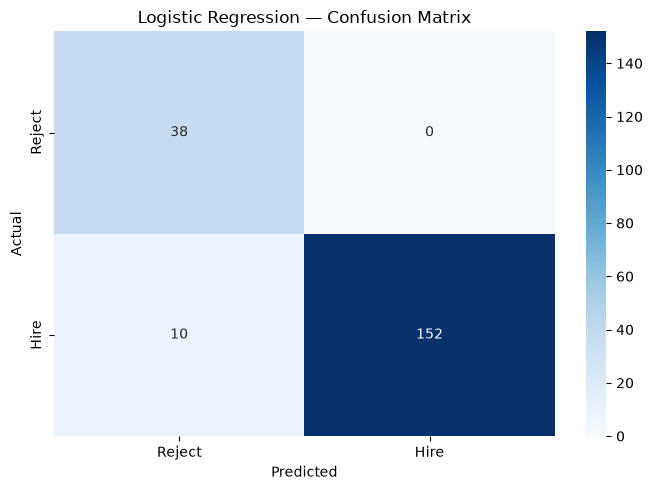

In [94]:
cm = confusion_matrix(
    y_test,
    logistic_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Reject", "Hire"],
    yticklabels=["Reject", "Hire"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [95]:
from sklearn.ensemble import RandomForestClassifier

In [96]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [97]:
random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Experience (Years)','Salary Expectation ($)','Projects Count',..., 'Project_Experience_Index','Education','Job Role']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

In [98]:
rf_predictions = random_forest_model.predict(X_test)

rf_probabilities = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

In [99]:
print("Random Forest")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("Precision:",
      round(
          precision_score(
              y_test,
              rf_predictions
          ),
          4
      ))

print("Recall:",
      round(
          recall_score(
              y_test,
              rf_predictions
          ),
          4
      ))

print("F1:",
      round(
          f1_score(
              y_test,
              rf_predictions
          ),
          4
      ))

print("ROC-AUC:",
      round(
          roc_auc_score(
              y_test,
              rf_probabilities
          ),
          4
      ))

Random Forest
Accuracy: 0.96
Precision: 0.9936
Recall: 0.9568
F1: 0.9748
ROC-AUC: 0.9963


In [100]:
model_results = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, dummy_predictions),
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(
            y_test,
            dummy_predictions,
            zero_division=0
        ),
        precision_score(
            y_test,
            logistic_predictions
        ),
        precision_score(
            y_test,
            rf_predictions
        )
    ],
    "Recall": [
        recall_score(
            y_test,
            dummy_predictions,
            zero_division=0
        ),
        recall_score(
            y_test,
            logistic_predictions
        ),
        recall_score(
            y_test,
            rf_predictions
        )
    ],
    "F1": [
        f1_score(
            y_test,
            dummy_predictions,
            zero_division=0
        ),
        f1_score(
            y_test,
            logistic_predictions
        ),
        f1_score(
            y_test,
            rf_predictions
        )
    ],
    "ROC-AUC": [
        np.nan,
        roc_auc_score(
            y_test,
            logistic_probabilities
        ),
        roc_auc_score(
            y_test,
            rf_probabilities
        )
    ]
})

model_results = model_results.round(4)

display(model_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy Baseline,0.81,0.8100,1.0000,0.8950,NaN
1,Logistic Regression,0.95,1.0000,0.9383,0.9682,0.9992
2,Random Forest,0.96,0.9936,0.9568,0.9748,0.9963


In [101]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost version: 3.4.1


In [102]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [103]:
from xgboost import XGBClassifier

In [104]:
hire_count = (y_train == 1).sum()
reject_count = (y_train == 0).sum()

scale_pos_weight = reject_count / hire_count

print("Hire:", hire_count)
print("Reject:", reject_count)
print("Scale ratio:", round(scale_pos_weight, 4))

Hire: 650
Reject: 150
Scale ratio: 0.2308


In [105]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [106]:
xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Experience (Years)','Salary Expectation ($)','Projects Count',..., 'Project_Experience_Index','Education','Job Role']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

In [107]:
xgb_predictions = xgb_model.predict(X_test)

xgb_probabilities = (
    xgb_model.predict_proba(X_test)[:, 1]
)

In [108]:
print("XGBoost")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, xgb_predictions), 4))

print("Precision:",
      round(
          precision_score(
              y_test,
              xgb_predictions
          ),
          4
      ))

print("Recall:",
      round(
          recall_score(
              y_test,
              xgb_predictions
          ),
          4
      ))

print("F1:",
      round(
          f1_score(
              y_test,
              xgb_predictions
          ),
          4
      ))

print("ROC-AUC:",
      round(
          roc_auc_score(
              y_test,
              xgb_probabilities
          ),
          4
      ))

XGBoost
Accuracy: 0.98
Precision: 0.9938
Recall: 0.9815
F1: 0.9876
ROC-AUC: 0.999


In [109]:
xgb_results = pd.DataFrame({
    "Model": ["XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, xgb_predictions)
    ],
    "Precision": [
        precision_score(y_test, xgb_predictions)
    ],
    "Recall": [
        recall_score(y_test, xgb_predictions)
    ],
    "F1": [
        f1_score(y_test, xgb_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, xgb_probabilities)
    ]
})

model_results = pd.concat(
    [model_results, xgb_results],
    ignore_index=True
).round(4)

display(model_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy Baseline,0.81,0.8100,1.0000,0.8950,NaN
1,Logistic Regression,0.95,1.0000,0.9383,0.9682,0.9992
2,Random Forest,0.96,0.9936,0.9568,0.9748,0.9963
3,XGBoost,0.98,0.9938,0.9815,0.9876,0.9990


In [110]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [111]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [112]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [113]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [114]:
logistic_cv = cross_validate(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression CV")
print("=" * 40)

for metric in scoring:
    values = logistic_cv[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

Logistic Regression CV
accuracy: 0.9680 ± 0.0117
precision: 1.0000 ± 0.0000
recall: 0.9606 ± 0.0143
f1: 0.9799 ± 0.0074
roc_auc: 0.9995 ± 0.0008


In [115]:
rf_cv = cross_validate(
    random_forest_model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest CV")
print("=" * 40)

for metric in scoring:
    values = rf_cv[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

Random Forest CV
accuracy: 0.9650 ± 0.0089
precision: 0.9912 ± 0.0050
recall: 0.9655 ± 0.0121
f1: 0.9781 ± 0.0057
roc_auc: 0.9961 ± 0.0021


In [116]:
xgb_cv = cross_validate(
    xgb_model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("XGBoost CV")
print("=" * 40)

for metric in scoring:
    values = xgb_cv[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

XGBoost CV
accuracy: 0.9830 ± 0.0093
precision: 0.9878 ± 0.0066
recall: 0.9914 ± 0.0092
f1: 0.9895 ± 0.0057
roc_auc: 0.9987 ± 0.0012


In [117]:
from sklearn.model_selection import RandomizedSearchCV

In [118]:
rf_parameters = {
    "classifier__n_estimators": [
        200,
        300,
        500,
        700
    ],
    
    "classifier__max_depth": [
        None,
        5,
        10,
        15,
        20
    ],
    
    "classifier__min_samples_split": [
        2,
        5,
        10
    ],
    
    "classifier__min_samples_leaf": [
        1,
        2,
        4
    ],
    
    "classifier__max_features": [
        "sqrt",
        "log2"
    ]
}

In [119]:
rf_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_parameters,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [120]:
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


KeyboardInterrupt: 

In [ ]:
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [None, 5, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maxim

In [ ]:
print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(round(rf_search.best_score_, 4))

Best parameters:
{'classifier__n_estimators': 500, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': None}

Best cross-validation ROC-AUC:
0.9967


In [ ]:
best_rf = rf_search.best_estimator_

In [ ]:
best_rf_predictions = best_rf.predict(X_test)

best_rf_probabilities = (
    best_rf.predict_proba(X_test)[:, 1]
)

In [ ]:
print("Optimized Random Forest")
print("=" * 40)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test,
            best_rf_predictions
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test,
            best_rf_predictions
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_test,
            best_rf_predictions
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_test,
            best_rf_predictions
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            best_rf_probabilities
        ),
        4
    )
)

Optimized Random Forest
Accuracy: 0.96
Precision: 0.9936
Recall: 0.9568
F1: 0.9748
ROC-AUC: 0.9969


In [ ]:
optimized_rf_results = pd.DataFrame({
    "Model": ["Optimized Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, best_rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, best_rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, best_rf_predictions)
    ],
    "F1": [
        f1_score(y_test, best_rf_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, best_rf_probabilities)
    ]
})

final_model_results = pd.concat(
    [model_results, optimized_rf_results],
    ignore_index=True
).round(4)

display(
    final_model_results.sort_values(
        "ROC-AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Logistic Regression,0.95,1.0000,0.9383,0.9682,0.9992
3,XGBoost,0.98,0.9938,0.9815,0.9876,0.9990
4,XGBoost,0.98,0.9938,0.9815,0.9876,0.9990
5,Optimized Random Forest,0.96,0.9936,0.9568,0.9748,0.9969
2,Random Forest,0.96,0.9936,0.9568,0.9748,0.9963
0,Dummy Baseline,0.81,0.8100,1.0000,0.8950,NaN


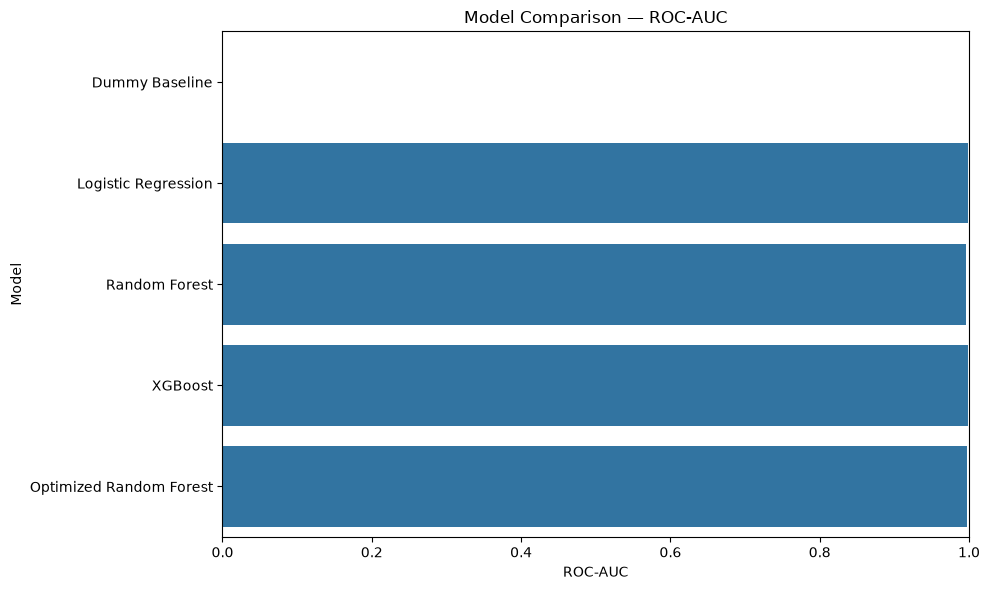

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_model_results,
    x="ROC-AUC",
    y="Model"
)

plt.xlim(0, 1)
plt.title("Model Comparison — ROC-AUC")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [ ]:
display(final_model_results.sort_values("ROC-AUC", ascending=False))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Logistic Regression,0.95,1.0000,0.9383,0.9682,0.9992
3,XGBoost,0.98,0.9938,0.9815,0.9876,0.9990
4,XGBoost,0.98,0.9938,0.9815,0.9876,0.9990
5,Optimized Random Forest,0.96,0.9936,0.9568,0.9748,0.9969
2,Random Forest,0.96,0.9936,0.9568,0.9748,0.9963
0,Dummy Baseline,0.81,0.8100,1.0000,0.8950,NaN


In [ ]:
final_model_results = (
    final_model_results
    .drop_duplicates(subset=["Model"])
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

display(final_model_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.95,1.0000,0.9383,0.9682,0.9992
1,XGBoost,0.98,0.9938,0.9815,0.9876,0.9990
2,Optimized Random Forest,0.96,0.9936,0.9568,0.9748,0.9969
3,Random Forest,0.96,0.9936,0.9568,0.9748,0.9963
4,Dummy Baseline,0.81,0.8100,1.0000,0.8950,NaN


In [ ]:
cv_models = {
    "Logistic Regression": logistic_cv,
    "Random Forest": rf_cv,
    "XGBoost": xgb_cv
}

cv_results = []

for model_name, results in cv_models.items():
    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": results["test_accuracy"].mean(),
        "Precision Mean": results["test_precision"].mean(),
        "Recall Mean": results["test_recall"].mean(),
        "F1 Mean": results["test_f1"].mean(),
        "ROC-AUC Mean": results["test_roc_auc"].mean(),
        "ROC-AUC Std": results["test_roc_auc"].std()
    })

cv_results_df = pd.DataFrame(cv_results).round(4)

display(
    cv_results_df.sort_values(
        "ROC-AUC Mean",
        ascending=False
    )
)

,Model,Accuracy Mean,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,ROC-AUC Std
0,Logistic Regression,0.968,1.0000,0.9606,0.9799,0.9995,0.0008
2,XGBoost,0.983,0.9878,0.9914,0.9895,0.9987,0.0012
1,Random Forest,0.965,0.9912,0.9655,0.9781,0.9961,0.0021


In [ ]:
cm_xgb = confusion_matrix(
    y_test,
    xgb_predictions
)

print("XGBoost Confusion Matrix:")
print(cm_xgb)

XGBoost Confusion Matrix:
[[ 37   1]
 [  3 159]]


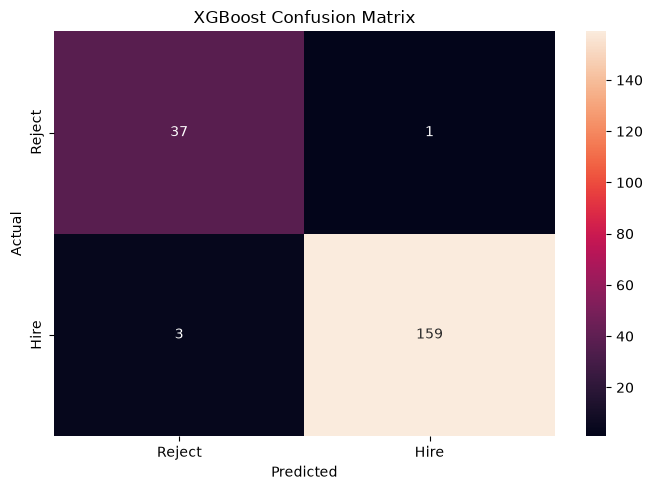

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    xticklabels=["Reject", "Hire"],
    yticklabels=["Reject", "Hire"]
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
print(
    df_clean.groupby("Recruiter Decision")[
        [
            "Experience (Years)",
            "Salary Expectation ($)",
            "Projects Count",
            "Skill_Count",
            "Certification_Count",
            "Project_Experience_Index"
        ]
    ].mean().round(2)
)

                    Experience (Years)  Salary Expectation ($)  \
Recruiter Decision                                               
Hire                              5.76                80483.02   
Reject                            1.17                77884.41   

                    Projects Count  Skill_Count  Certification_Count  \
Recruiter Decision                                                     
Hire                          5.65         3.05                 0.74   
Reject                        2.91         2.87                 0.67   

                    Project_Experience_Index  
Recruiter Decision                            
Hire                                   35.27  
Reject                                  5.07  


In [ ]:
display(target_correlation.round(3))

AI Score (0-100)            0.841
Experience (Years)          0.576
Project_Experience_Index    0.452
Projects Count              0.331
Skill_Count                 0.086
Certification_Count         0.060
Salary Expectation ($)      0.044
Name: Target_Binary, dtype: float64

In [ ]:
ML_FEATURES_WITH_AI = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index",
    "AI Score (0-100)",
    "Education",
    "Job Role"
]

X_ai = df_clean[ML_FEATURES_WITH_AI].copy()
y_ai = df_clean["Target_Binary"].copy()

In [ ]:
X_train_ai, X_test_ai, y_train_ai, y_test_ai = train_test_split(
    X_ai,
    y_ai,
    test_size=0.20,
    random_state=42,
    stratify=y_ai
)

In [ ]:
numeric_features_ai = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index",
    "AI Score (0-100)"
]

In [ ]:
numeric_transformer_ai = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer_ai = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor_ai = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_ai,
            numeric_features_ai
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [ ]:
xgb_ai_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ai),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [ ]:
xgb_ai_model.fit(
    X_train_ai,
    y_train_ai
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Experience (Years)','Salary Expectation ($)','Projects Count',..., 'AI Score (0-100)','Education','Job Role']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [ ]:
xgb_ai_predictions = xgb_ai_model.predict(X_test_ai)

xgb_ai_probabilities = (
    xgb_ai_model.predict_proba(X_test_ai)[:, 1]
)

print("XGBoost + AI Score")
print("=" * 40)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test_ai,
            xgb_ai_predictions
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test_ai,
            xgb_ai_predictions
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_test_ai,
            xgb_ai_predictions
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_test_ai,
            xgb_ai_predictions
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test_ai,
            xgb_ai_probabilities
        ),
        4
    )
)

XGBoost + AI Score
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0
ROC-AUC: 1.0


In [ ]:
display(cv_results_df.sort_values("ROC-AUC Mean", ascending=False))

,Model,Accuracy Mean,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,ROC-AUC Std
0,Logistic Regression,0.968,1.0000,0.9606,0.9799,0.9995,0.0008
2,XGBoost,0.983,0.9878,0.9914,0.9895,0.9987,0.0012
1,Random Forest,0.965,0.9912,0.9655,0.9781,0.9961,0.0021


In [ ]:
print(cm_xgb)

[[ 37   1]
 [  3 159]]


In [ ]:
ML_FEATURES_WITH_AI = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index",
    "AI Score (0-100)",
    "Education",
    "Job Role"
]

X_ai = df_clean[ML_FEATURES_WITH_AI].copy()
y_ai = df_clean["Target_Binary"].copy()

X_train_ai, X_test_ai, y_train_ai, y_test_ai = train_test_split(
    X_ai,
    y_ai,
    test_size=0.20,
    random_state=42,
    stratify=y_ai
)

numeric_features_ai = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "Project_Experience_Index",
    "AI Score (0-100)"
]

numeric_transformer_ai = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer_ai = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor_ai = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_ai, numeric_features_ai),
        ("cat", categorical_transformer_ai, categorical_features)
    ]
)

xgb_ai_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ai),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

xgb_ai_model.fit(X_train_ai, y_train_ai)

xgb_ai_predictions = xgb_ai_model.predict(X_test_ai)
xgb_ai_probabilities = xgb_ai_model.predict_proba(X_test_ai)[:, 1]

print("XGBoost + AI Score")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_test_ai, xgb_ai_predictions), 4))

print("Precision:",
      round(precision_score(y_test_ai, xgb_ai_predictions), 4))

print("Recall:",
      round(recall_score(y_test_ai, xgb_ai_predictions), 4))

print("F1:",
      round(f1_score(y_test_ai, xgb_ai_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test_ai, xgb_ai_probabilities), 4))

XGBoost + AI Score
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0
ROC-AUC: 1.0


In [ ]:
print(
    df_clean.groupby("Recruiter Decision")[
        "AI Score (0-100)"
    ].agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ]).round(2)
)

                    count   mean  median  min  max
Recruiter Decision                                
Hire                  812  92.43   100.0   65  100
Reject                188  47.31    50.0   15   60


In [ ]:
print(
    df_clean[
        ["AI Score (0-100)", "Target_Binary"]
    ].corr().round(4)
)

                  AI Score (0-100)  Target_Binary
AI Score (0-100)            1.0000         0.8405
Target_Binary               0.8405         1.0000


In [ ]:
%pip install shap

  Using cached shap-0.52.0-cp312-abi3-win_amd64.whl.metadata (26 kB)
Using cached shap-0.52.0-cp312-abi3-win_amd64.whl (499 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import shap

print("SHAP version:", shap.__version__)

c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.52.0


In [ ]:
xgb_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Experience (Years)','Salary Expectation ($)','Projects Count',..., 'Project_Experience_Index','Education','Job Role']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

In [ ]:
xgb_classifier = xgb_model.named_steps["classifier"]
xgb_preprocessor = xgb_model.named_steps["preprocessor"]

print(xgb_classifier)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [ ]:
X_test_transformed = xgb_preprocessor.transform(X_test)

print("Original test shape:", X_test.shape)
print("Transformed test shape:", X_test_transformed.shape)

Original test shape: (200, 8)
Transformed test shape: (200, 15)


In [ ]:
feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 15
['num__Experience (Years)' 'num__Salary Expectation ($)'
 'num__Projects Count' 'num__Skill_Count' 'num__Certification_Count'
 'num__Project_Experience_Index' 'cat__Education_B.Sc'
 'cat__Education_B.Tech' 'cat__Education_M.Tech' 'cat__Education_MBA'
 'cat__Education_PhD' 'cat__Job Role_AI Researcher'
 'cat__Job Role_Cybersecurity Analyst' 'cat__Job Role_Data Scientist'
 'cat__Job Role_Software Engineer']


In [ ]:
explainer = shap.TreeExplainer(
    xgb_classifier
)

shap_values = explainer.shap_values(
    X_test_transformed
)

print("SHAP values shape:", np.array(shap_values).shape)

SHAP values shape: (200, 15)


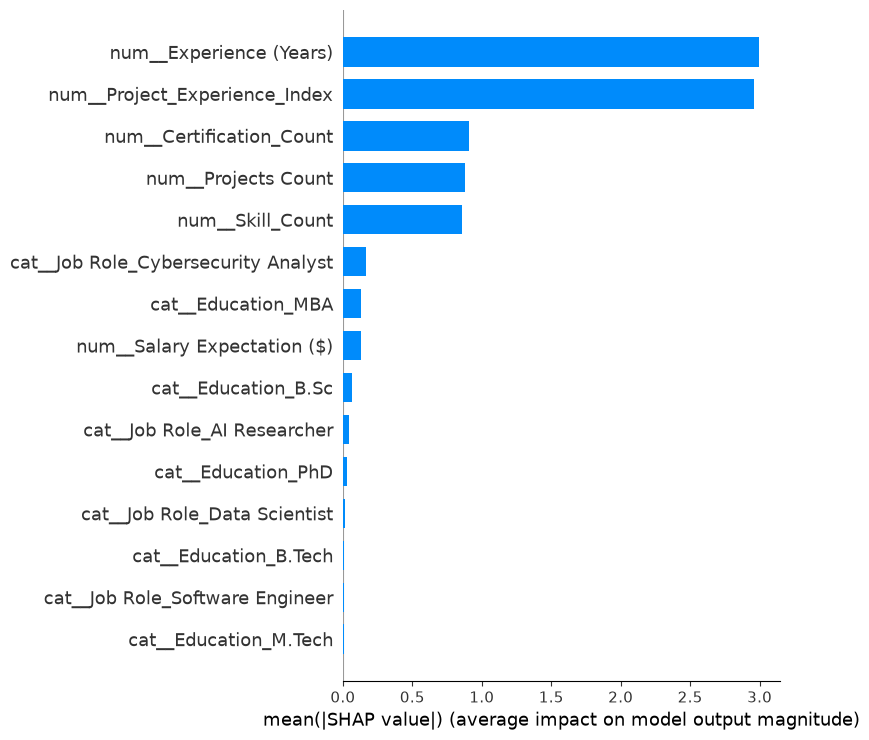

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

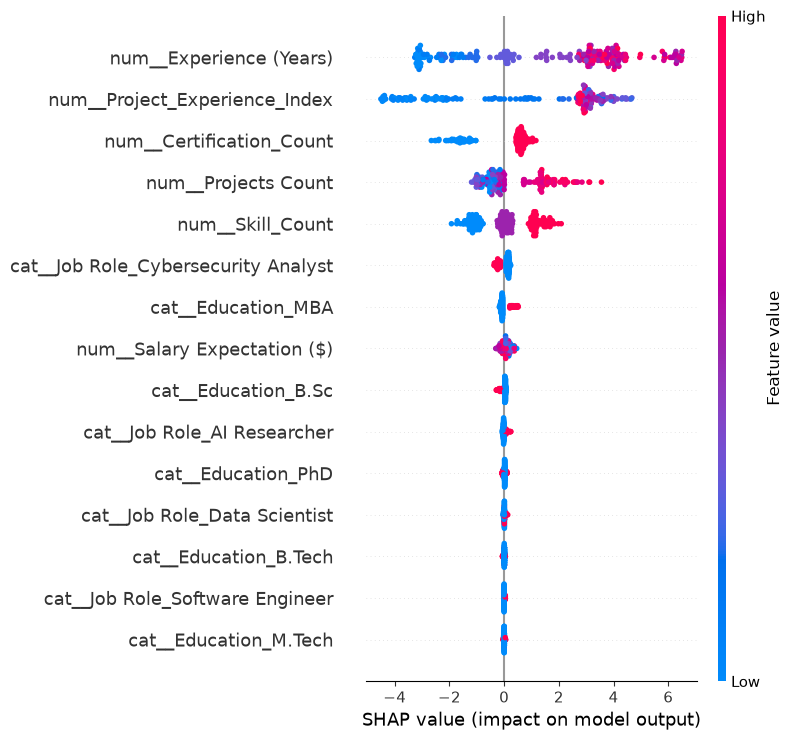

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)

In [ ]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(shap_importance.head(15))

,Feature,Mean_Absolute_SHAP
0,num__Experience (Years),2.996880
1,num__Project_Experience_Index,2.957570
2,num__Certification_Count,0.905278
3,num__Projects Count,0.879400
4,num__Skill_Count,0.860796
5,cat__Job Role_Cybersecurity Analyst,0.167848
6,cat__Education_MBA,0.132399
7,num__Salary Expectation ($),0.127736
8,cat__Education_B.Sc,0.062729
9,cat__Job Role_AI Researcher,0.043574


In [ ]:
candidate_index = 0

candidate = X_test.iloc[[candidate_index]]

print("Candidate:")
display(candidate)

Candidate:


,Experience (Years),Salary Expectation ($),Projects Count,Skill_Count,Certification_Count,Project_Experience_Index,Education,Job Role
38,7,106469,0,2,0,0,PhD,Cybersecurity Analyst


In [ ]:
candidate_prediction = xgb_model.predict(candidate)[0]

candidate_probability = (
    xgb_model.predict_proba(candidate)[0, 1]
)

print(
    "Prediction:",
    "Hire" if candidate_prediction == 1 else "Reject"
)

print(
    "Hire probability:",
    round(candidate_probability * 100, 2),
    "%"
)

Prediction: Hire
Hire probability: 93.96 %


In [ ]:
candidate_shap = shap_values[candidate_index]

In [ ]:
candidate_explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": candidate_shap,
    "Absolute_Impact": np.abs(candidate_shap)
})

candidate_explanation = (
    candidate_explanation
    .sort_values(
        "Absolute_Impact",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    candidate_explanation.head(10)
)

,Feature,SHAP_Value,Absolute_Impact
0,num__Experience (Years),6.289766,6.289766
1,num__Project_Experience_Index,-2.122780,2.122780
2,num__Certification_Count,-1.152465,1.152465
3,num__Skill_Count,-0.908388,0.908388
4,num__Projects Count,-0.492613,0.492613
5,cat__Job Role_Cybersecurity Analyst,-0.191389,0.191389
6,cat__Education_MBA,-0.110980,0.110980
7,num__Salary Expectation ($),-0.039253,0.039253
8,cat__Education_PhD,0.038272,0.038272
9,cat__Job Role_AI Researcher,-0.031592,0.031592


In [ ]:
positive_factors = (
    candidate_explanation[
        candidate_explanation["SHAP_Value"] > 0
    ]
    .head(5)
)

negative_factors = (
    candidate_explanation[
        candidate_explanation["SHAP_Value"] < 0
    ]
    .sort_values(
        "SHAP_Value"
    )
    .head(5)
)

print("Positive factors:")
display(positive_factors)

print("\nNegative factors:")
display(negative_factors)

Positive factors:


,Feature,SHAP_Value,Absolute_Impact
0,num__Experience (Years),6.289766,6.289766
8,cat__Education_PhD,0.038272,0.038272
10,cat__Education_B.Sc,0.021559,0.021559
14,cat__Education_M.Tech,0.002573,0.002573



Negative factors:


,Feature,SHAP_Value,Absolute_Impact
1,num__Project_Experience_Index,-2.122780,2.122780
2,num__Certification_Count,-1.152465,1.152465
3,num__Skill_Count,-0.908388,0.908388
4,num__Projects Count,-0.492613,0.492613
5,cat__Job Role_Cybersecurity Analyst,-0.191389,0.191389


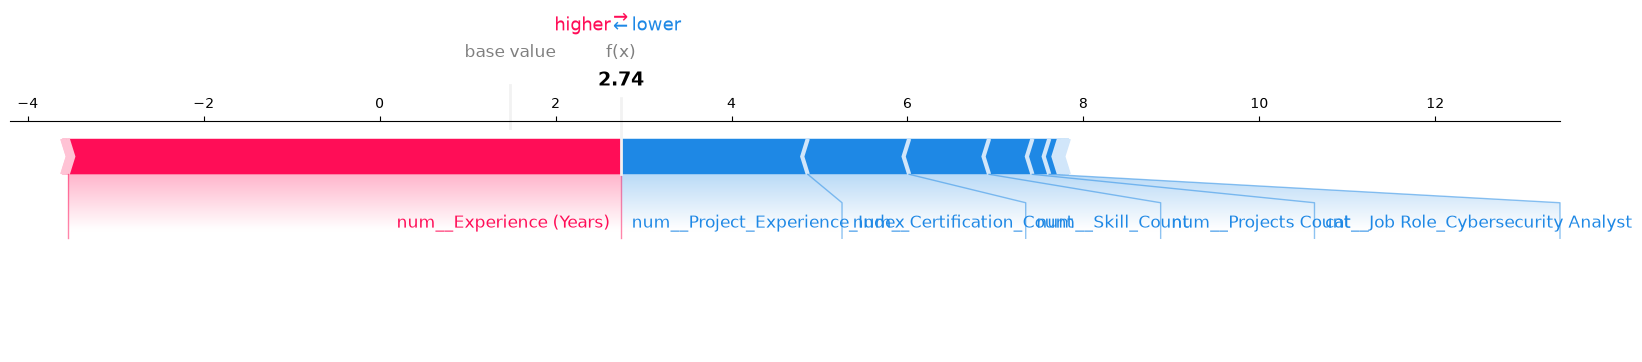

<Figure size 640x480 with 0 Axes>

In [ ]:
shap.force_plot(
    explainer.expected_value,
    candidate_shap,
    feature_names=feature_names,
    matplotlib=True
)

plt.tight_layout()
plt.show()

In [ ]:
def explain_candidate(candidate_index):
    
    candidate = X_test.iloc[[candidate_index]]
    
    prediction = xgb_model.predict(candidate)[0]
    probability = xgb_model.predict_proba(candidate)[0, 1]
    
    transformed_candidate = (
        xgb_preprocessor.transform(candidate)
    )
    
    candidate_shap = explainer.shap_values(
        transformed_candidate
    )[0]
    
    explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": candidate_shap
    })
    
    explanation["Absolute_Impact"] = (
        explanation["SHAP_Value"].abs()
    )
    
    explanation = explanation.sort_values(
        "Absolute_Impact",
        ascending=False
    )
    
    positive = explanation[
        explanation["SHAP_Value"] > 0
    ].head(3)
    
    negative = explanation[
        explanation["SHAP_Value"] < 0
    ].sort_values(
        "SHAP_Value"
    ).head(3)
    
    print("=" * 60)
    print("CANDIDATE AI EXPLANATION")
    print("=" * 60)
    
    print(
        "Prediction:",
        "HIRE" if prediction == 1 else "REJECT"
    )
    
    print(
        "Hire Probability:",
        f"{probability * 100:.2f}%"
    )
    
    print("\nTop Positive Factors:")
    
    for _, row in positive.iterrows():
        print(
            f"  + {row['Feature']}: "
            f"{row['SHAP_Value']:.4f}"
        )
    
    print("\nTop Negative Factors:")
    
    for _, row in negative.iterrows():
        print(
            f"  - {row['Feature']}: "
            f"{row['SHAP_Value']:.4f}"
        )
    
    return explanation

In [ ]:
candidate_explanation = explain_candidate(0)

CANDIDATE AI EXPLANATION
Prediction: HIRE
Hire Probability: 93.96%

Top Positive Factors:
  + num__Experience (Years): 6.2898
  + cat__Education_PhD: 0.0383
  + cat__Education_B.Sc: 0.0216

Top Negative Factors:
  - num__Project_Experience_Index: -2.1228
  - num__Certification_Count: -1.1525
  - num__Skill_Count: -0.9084


In [ ]:
fairness_df = X_test.copy()

fairness_df["Actual_Decision"] = y_test.values
fairness_df["Predicted_Decision"] = xgb_predictions
fairness_df["Hire_Probability"] = xgb_probabilities

fairness_df["Actual_Label"] = fairness_df["Actual_Decision"].map({
    0: "Reject",
    1: "Hire"
})

fairness_df["Predicted_Label"] = fairness_df["Predicted_Decision"].map({
    0: "Reject",
    1: "Hire"
})

print("Fairness analysis dataset:")
print(fairness_df.shape)

display(fairness_df.head())

Fairness analysis dataset:
(200, 13)


,Experience (Years),Salary Expectation ($),Projects Count,Skill_Count,Certification_Count,Project_Experience_Index,Education,Job Role,Actual_Decision,Predicted_Decision,Hire_Probability,Actual_Label,Predicted_Label
38,7,106469,0,2,0,0,PhD,Cybersecurity Analyst,1,1,0.939589,Hire,Hire
8,7,92270,3,2,1,24,MBA,Cybersecurity Analyst,1,1,0.999209,Hire,Hire
907,0,72251,6,3,1,6,B.Tech,Data Scientist,0,0,0.001700,Reject,Reject
981,10,100218,10,2,1,110,PhD,AI Researcher,1,1,0.999811,Hire,Hire
543,6,119478,2,2,1,14,B.Sc,Cybersecurity Analyst,1,1,0.997561,Hire,Hire


In [ ]:
# ============================================
# EDUCATION FAIRNESS ANALYSIS
# ============================================

# Create fairness dataframe from XGBoost test predictions
fairness_df = X_test.copy()

fairness_df["Actual_Decision"] = y_test.values
fairness_df["Predicted_Decision"] = xgb_predictions
fairness_df["Hire_Probability"] = xgb_probabilities

# Calculate education-level statistics
education_fairness = (
    fairness_df
    .groupby("Education")
    .agg(
        Candidates=("Predicted_Decision", "count"),
        Actual_Hire_Rate=("Actual_Decision", "mean"),
        Predicted_Hire_Rate=("Predicted_Decision", "mean"),
        Average_Hire_Probability=("Hire_Probability", "mean")
    )
)

# Convert rates to percentages
education_fairness["Actual_Hire_Rate"] *= 100
education_fairness["Predicted_Hire_Rate"] *= 100
education_fairness["Average_Hire_Probability"] *= 100

education_fairness = education_fairness.round(2)

print("Education Fairness Analysis")
print("=" * 50)

display(education_fairness)

Education Fairness Analysis


,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Education,,,,
B.Sc,44,81.82,81.82,82.400002
B.Tech,41,85.37,85.37,84.449997
M.Tech,31,83.87,83.87,83.839996
MBA,36,77.78,75.00,75.040001
PhD,48,77.08,75.00,76.190002


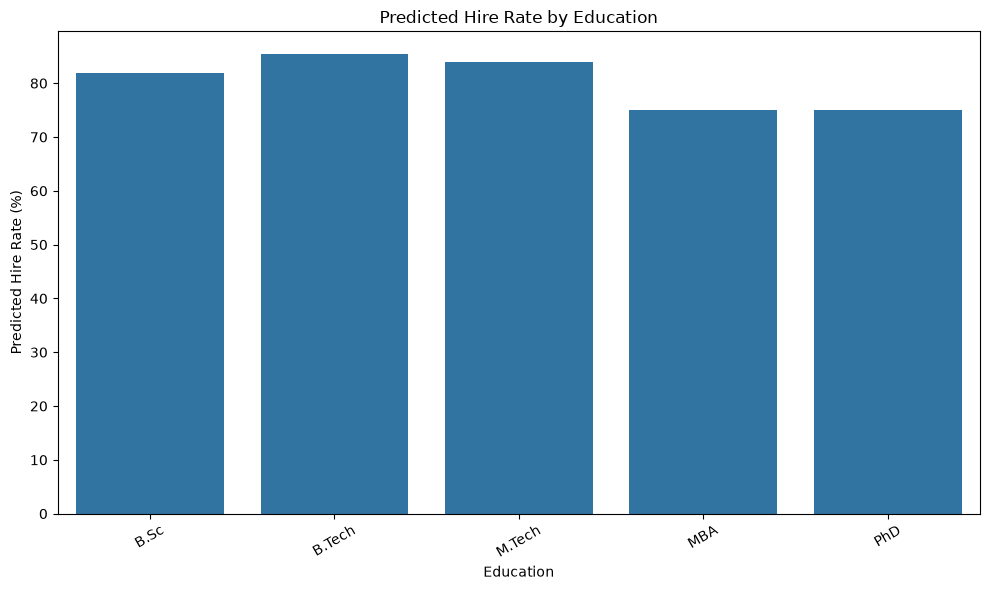

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=education_fairness.reset_index(),
    x="Education",
    y="Predicted_Hire_Rate"
)

plt.title("Predicted Hire Rate by Education")
plt.xlabel("Education")
plt.ylabel("Predicted Hire Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
role_fairness = (
    fairness_df
    .groupby("Job Role")
    .agg(
        Candidates=("Predicted_Decision", "count"),
        Actual_Hire_Rate=("Actual_Decision", "mean"),
        Predicted_Hire_Rate=("Predicted_Decision", "mean"),
        Average_Hire_Probability=("Hire_Probability", "mean")
    )
)

role_fairness["Actual_Hire_Rate"] *= 100
role_fairness["Predicted_Hire_Rate"] *= 100
role_fairness["Average_Hire_Probability"] *= 100

role_fairness = role_fairness.round(2)

display(role_fairness)

,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Job Role,,,,
AI Researcher,45,84.44,84.44,84.309998
Cybersecurity Analyst,50,80.00,76.00,77.160004
Data Scientist,63,74.60,74.60,75.040001
Software Engineer,42,88.10,88.10,87.290001


In [ ]:
fairness_df["Experience_Group"] = pd.cut(
    fairness_df["Experience (Years)"],
    bins=[-1, 1, 3, 5, 10, np.inf],
    labels=[
        "Fresher",
        "Junior",
        "Mid-Level",
        "Senior",
        "Expert"
    ]
)

experience_fairness = (
    fairness_df
    .groupby("Experience_Group", observed=True)
    .agg(
        Candidates=("Predicted_Decision", "count"),
        Actual_Hire_Rate=("Actual_Decision", "mean"),
        Predicted_Hire_Rate=("Predicted_Decision", "mean"),
        Average_Hire_Probability=("Hire_Probability", "mean")
    )
)

experience_fairness["Actual_Hire_Rate"] *= 100
experience_fairness["Predicted_Hire_Rate"] *= 100
experience_fairness["Average_Hire_Probability"] *= 100

experience_fairness = experience_fairness.round(2)

display(experience_fairness)

,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Experience_Group,,,,
Fresher,39,33.33,30.77,32.270000
Junior,39,71.79,69.23,71.830002
Mid-Level,38,97.37,97.37,95.029999
Senior,84,100.00,100.00,99.699997


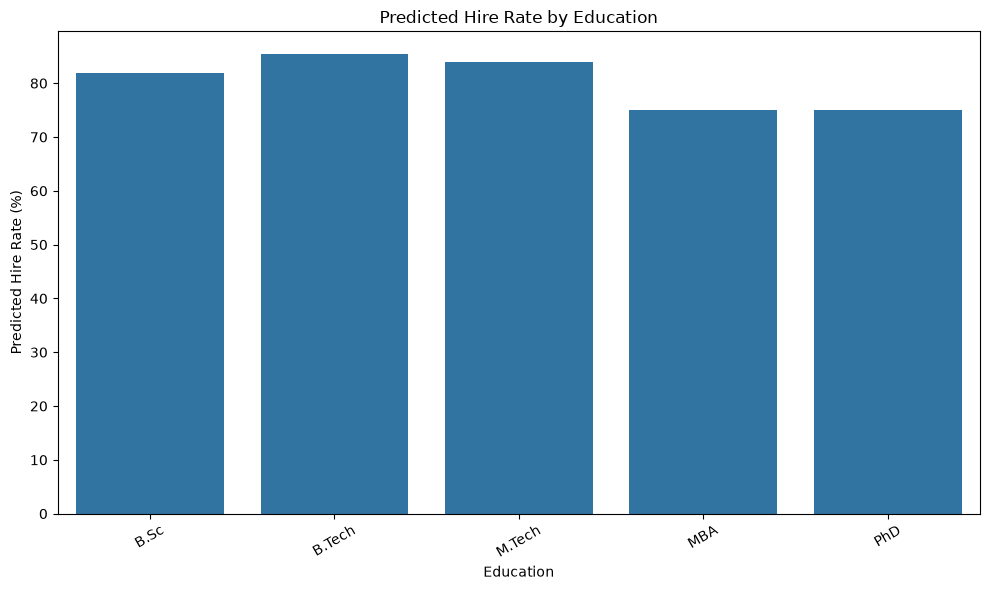

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=education_fairness.reset_index(),
    x="Education",
    y="Predicted_Hire_Rate"
)

plt.title("Predicted Hire Rate by Education")
plt.xlabel("Education")
plt.ylabel("Predicted Hire Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
role_fairness = (
    fairness_df
    .groupby("Job Role")
    .agg(
        Candidates=("Predicted_Decision", "count"),
        Actual_Hire_Rate=("Actual_Decision", "mean"),
        Predicted_Hire_Rate=("Predicted_Decision", "mean"),
        Average_Hire_Probability=("Hire_Probability", "mean")
    )
)

role_fairness["Actual_Hire_Rate"] *= 100
role_fairness["Predicted_Hire_Rate"] *= 100
role_fairness["Average_Hire_Probability"] *= 100

role_fairness = role_fairness.round(2)

display(role_fairness)

,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Job Role,,,,
AI Researcher,45,84.44,84.44,84.309998
Cybersecurity Analyst,50,80.00,76.00,77.160004
Data Scientist,63,74.60,74.60,75.040001
Software Engineer,42,88.10,88.10,87.290001


In [ ]:
fairness_df["Experience_Group"] = pd.cut(
    fairness_df["Experience (Years)"],
    bins=[-1, 1, 3, 5, 10, np.inf],
    labels=[
        "Fresher",
        "Junior",
        "Mid-Level",
        "Senior",
        "Expert"
    ]
)

In [ ]:
def group_error_analysis(data, group_column):
    
    results = []
    
    for group, group_data in data.groupby(
        group_column,
        observed=True
    ):
        
        actual = group_data["Actual_Decision"]
        predicted = group_data["Predicted_Decision"]
        
        tn, fp, fn, tp = confusion_matrix(
            actual,
            predicted,
            labels=[0, 1]
        ).ravel()
        
        results.append({
            "Group": group,
            "Candidates": len(group_data),
            "Hire_Rate": predicted.mean() * 100,
            "False_Positive_Rate": (
                fp / (fp + tn) * 100
                if (fp + tn) > 0 else 0
            ),
            "False_Negative_Rate": (
                fn / (fn + tp) * 100
                if (fn + tp) > 0 else 0
            ),
            "Recall": (
                tp / (tp + fn)
                if (tp + fn) > 0 else 0
            )
        })
    
    return pd.DataFrame(results).round(3)

In [ ]:
education_errors = group_error_analysis(
    fairness_df,
    "Education"
)

display(education_errors)

,Group,Candidates,Hire_Rate,False_Positive_Rate,False_Negative_Rate,Recall
0,B.Sc,44,81.818,12.5,2.778,0.972
1,B.Tech,41,85.366,0.0,0.000,1.000
2,M.Tech,31,83.871,0.0,0.000,1.000
3,MBA,36,75.000,0.0,3.571,0.964
4,PhD,48,75.000,0.0,2.703,0.973


In [ ]:
experience_errors = group_error_analysis(
    fairness_df,
    "Experience_Group"
)

display(experience_errors)

,Group,Candidates,Hire_Rate,False_Positive_Rate,False_Negative_Rate,Recall
0,Fresher,39,30.769,0.0,7.692,0.923
1,Junior,39,69.231,0.0,3.571,0.964
2,Mid-Level,38,97.368,100.0,2.703,0.973
3,Senior,84,100.000,0.0,0.000,1.000


In [ ]:
role_errors = group_error_analysis(
    fairness_df,
    "Job Role"
)

display(role_errors)

,Group,Candidates,Hire_Rate,False_Positive_Rate,False_Negative_Rate,Recall
0,AI Researcher,45,84.444,0.00,0.000,1.000
1,Cybersecurity Analyst,50,76.000,0.00,5.000,0.950
2,Data Scientist,63,74.603,6.25,2.128,0.979
3,Software Engineer,42,88.095,0.00,0.000,1.000


In [ ]:
experience_errors = group_error_analysis(
    fairness_df,
    "Experience_Group"
)

display(experience_errors)

,Group,Candidates,Hire_Rate,False_Positive_Rate,False_Negative_Rate,Recall
0,Fresher,39,30.769,0.0,7.692,0.923
1,Junior,39,69.231,0.0,3.571,0.964
2,Mid-Level,38,97.368,100.0,2.703,0.973
3,Senior,84,100.000,0.0,0.000,1.000


In [ ]:
education_rates = education_fairness[
    "Predicted_Hire_Rate"
]

education_selection_ratio = (
    education_rates.min() /
    education_rates.max()
)

print(
    "Education selection-rate ratio:",
    round(education_selection_ratio, 3)
)

Education selection-rate ratio: 0.879


In [ ]:
role_rates = role_fairness[
    "Predicted_Hire_Rate"
]

role_selection_ratio = (
    role_rates.min() /
    role_rates.max()
)

print(
    "Job-role selection-rate ratio:",
    round(role_selection_ratio, 3)
)

Job-role selection-rate ratio: 0.847


In [ ]:
fairness_df["Salary_Group"] = pd.qcut(
    fairness_df["Salary Expectation ($)"],
    q=4,
    duplicates="drop"
)

In [ ]:
salary_analysis = (
    fairness_df
    .groupby("Salary_Group", observed=True)
    .agg(
        Candidates=("Predicted_Decision", "count"),
        Average_Salary=("Salary Expectation ($)", "mean"),
        Actual_Hire_Rate=("Actual_Decision", "mean"),
        Predicted_Hire_Rate=("Predicted_Decision", "mean"),
        Average_Hire_Probability=("Hire_Probability", "mean")
    )
)

salary_analysis["Actual_Hire_Rate"] *= 100
salary_analysis["Predicted_Hire_Rate"] *= 100
salary_analysis["Average_Hire_Probability"] *= 100

display(salary_analysis.round(2))

,Candidates,Average_Salary,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Salary_Group,,,,,
"(40594.999, 59088.25]",50,49822.98,78.0,78.0,78.190002
"(59088.25, 76618.5]",50,65816.16,74.0,74.0,74.169998
"(76618.5, 99191.25]",50,89039.94,80.0,80.0,79.480003
"(99191.25, 119478.0]",50,110363.96,92.0,88.0,89.070000


In [ ]:
print("=" * 70)
print("AI HIRING MODEL — FAIRNESS AUDIT")
print("=" * 70)

print("\nEducation:")
display(education_fairness)

print("\nJob Role:")
display(role_fairness)

print("\nExperience:")
display(experience_fairness)

print("\nSalary:")
display(salary_analysis.round(2))

AI HIRING MODEL — FAIRNESS AUDIT

Education:


,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Education,,,,
B.Sc,44,81.82,81.82,82.400002
B.Tech,41,85.37,85.37,84.449997
M.Tech,31,83.87,83.87,83.839996
MBA,36,77.78,75.00,75.040001
PhD,48,77.08,75.00,76.190002



Job Role:


,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Job Role,,,,
AI Researcher,45,84.44,84.44,84.309998
Cybersecurity Analyst,50,80.00,76.00,77.160004
Data Scientist,63,74.60,74.60,75.040001
Software Engineer,42,88.10,88.10,87.290001



Experience:


,Candidates,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Experience_Group,,,,
Fresher,39,33.33,30.77,32.270000
Junior,39,71.79,69.23,71.830002
Mid-Level,38,97.37,97.37,95.029999
Senior,84,100.00,100.00,99.699997



Salary:


,Candidates,Average_Salary,Actual_Hire_Rate,Predicted_Hire_Rate,Average_Hire_Probability
Salary_Group,,,,,
"(40594.999, 59088.25]",50,49822.98,78.0,78.0,78.190002
"(59088.25, 76618.5]",50,65816.16,74.0,74.0,74.169998
"(76618.5, 99191.25]",50,89039.94,80.0,80.0,79.480003
"(99191.25, 119478.0]",50,110363.96,92.0,88.0,89.070000


In [ ]:
# Features used by our final resume-based model
X_all = df_clean[ML_FEATURES].copy()

# Actual target
y_all = df_clean[TARGET_COLUMN].copy()

# Generate predictions
all_predictions = xgb_model.predict(X_all)

all_probabilities = xgb_model.predict_proba(X_all)[:, 1]

print("Candidates:", len(X_all))
print("Predictions:", len(all_predictions))
print("Probabilities:", len(all_probabilities))

Candidates: 1000
Predictions: 1000
Probabilities: 1000


In [ ]:
ranking_df = df_clean[
    [
        "Resume_ID",
        "Name",
        "Skills",
        "Experience (Years)",
        "Education",
        "Certifications",
        "Job Role",
        "Salary Expectation ($)",
        "Projects Count",
        "AI Score (0-100)"
    ]
].copy()

ranking_df["Hire_Probability"] = (
    all_probabilities * 100
)

ranking_df["Predicted_Decision"] = (
    all_predictions
)

ranking_df["Predicted_Decision_Label"] = (
    ranking_df["Predicted_Decision"]
    .map({
        0: "Reject",
        1: "Hire"
    })
)

print("Ranking dataset created:")
print(ranking_df.shape)

display(ranking_df.head())

Ranking dataset created:
(1000, 13)


,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Salary Expectation ($),Projects Count,AI Score (0-100),Hire_Probability,Predicted_Decision,Predicted_Decision_Label
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,<NA>,AI Researcher,104895,8,100,99.951813,1,Hire
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,113002,1,100,99.991440,1,Hire
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,71766,7,70,99.525108,1,Hire
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,46848,0,95,99.461815,1,Hire
4,5,Julie Hill,"SQL, React, Java",4,PhD,<NA>,Software Engineer,87441,9,100,99.869423,1,Hire


In [ ]:
def recommendation_level(probability):
    
    if probability >= 90:
        return "Strong Hire"
    
    elif probability >= 75:
        return "Hire"
    
    elif probability >= 50:
        return "Review"
    
    else:
        return "Reject"

In [ ]:
ranking_df["Recommendation"] = (
    ranking_df["Hire_Probability"]
    .apply(recommendation_level)
)

In [ ]:
print(
    ranking_df["Recommendation"]
    .value_counts()
)

Recommendation
Strong Hire    794
Reject         190
Hire            14
Review           2
Name: count, dtype: int64


In [ ]:
ranking_df = (
    ranking_df
    .sort_values(
        "Hire_Probability",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking_df["Rank"] = (
    ranking_df.index + 1
)

In [ ]:
# ============================================
# STEP 9 — CANDIDATE RANKING ENGINE
# ============================================

X_all = df_clean[ML_FEATURES].copy()

all_predictions = xgb_model.predict(X_all)
all_probabilities = xgb_model.predict_proba(X_all)[:, 1]

print("Total candidates:", len(X_all))
print("Predictions generated:", len(all_predictions))

Total candidates: 1000
Predictions generated: 1000


In [ ]:
def recommendation_level(probability):
    
    if probability >= 90:
        return "Strong Hire"
    
    elif probability >= 75:
        return "Hire"
    
    elif probability >= 50:
        return "Review"
    
    else:
        return "Reject"

In [ ]:
ranking_df["Recommendation"] = (
    ranking_df["Hire_Probability"]
    .apply(recommendation_level)
)

In [ ]:
print(
    ranking_df["Recommendation"]
    .value_counts()
)

Recommendation
Strong Hire    794
Reject         190
Hire            14
Review           2
Name: count, dtype: int64


In [ ]:
ranking_df = (
    ranking_df
    .sort_values(
        "Hire_Probability",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking_df["Rank"] = (
    ranking_df.index + 1
)

In [ ]:
# ============================================================
# STEP 9 — CANDIDATE RANKING ENGINE
# COMPLETE REBUILD
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

print("=" * 70)
print("BUILDING CANDIDATE RANKING ENGINE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Verify required columns exist
# ------------------------------------------------------------

required_columns = [
    "Resume_ID",
    "Name",
    "Skills",
    "Experience (Years)",
    "Education",
    "Certifications",
    "Job Role",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "AI Score (0-100)"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in df_clean: {missing_columns}"
    )

print("✓ All required columns found")


# ------------------------------------------------------------
# 2. Verify model variables
# ------------------------------------------------------------

if "xgb_model" not in globals():
    raise ValueError(
        "xgb_model does not exist. "
        "Run the XGBoost training cell first."
    )

print("✓ XGBoost model found")


# ------------------------------------------------------------
# 3. Generate predictions for ALL candidates
# ------------------------------------------------------------

X_all = df_clean[ML_FEATURES].copy()

all_predictions = xgb_model.predict(X_all)

all_probabilities = (
    xgb_model.predict_proba(X_all)[:, 1]
)

print("✓ Predictions generated")
print("Candidates:", len(X_all))


# ------------------------------------------------------------
# 4. Build ranking dataframe DIRECTLY from df_clean
# ------------------------------------------------------------

ranking_df = df_clean[required_columns].copy()

ranking_df["Hire_Probability"] = (
    all_probabilities * 100
)

ranking_df["Predicted_Decision"] = (
    all_predictions
)

ranking_df["Predicted_Decision_Label"] = (
    ranking_df["Predicted_Decision"]
    .map({
        0: "Reject",
        1: "Hire"
    })
)


# ------------------------------------------------------------
# 5. Recommendation category
# ------------------------------------------------------------

def recommendation_level(probability):

    if probability >= 90:
        return "Strong Hire"

    elif probability >= 75:
        return "Hire"

    elif probability >= 50:
        return "Review"

    else:
        return "Reject"


ranking_df["Recommendation"] = (
    ranking_df["Hire_Probability"]
    .apply(recommendation_level)
)


# ------------------------------------------------------------
# 6. Candidate strength score
# ------------------------------------------------------------

strength_features = [
    "Experience (Years)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count"
]

strength_scaler = MinMaxScaler()

strength_values = strength_scaler.fit_transform(
    df_clean[strength_features]
)

strength_df = pd.DataFrame(
    strength_values,
    columns=strength_features,
    index=df_clean.index
)

ranking_df["Candidate_Strength_Score"] = (
    strength_df["Experience (Years)"] * 0.35
    +
    strength_df["Projects Count"] * 0.25
    +
    strength_df["Skill_Count"] * 0.25
    +
    strength_df["Certification_Count"] * 0.15
) * 100


# ------------------------------------------------------------
# 7. Final candidate score
# ------------------------------------------------------------

ranking_df["Final_Candidate_Score"] = (
    ranking_df["Hire_Probability"] * 0.80
    +
    ranking_df["Candidate_Strength_Score"] * 0.20
)


# ------------------------------------------------------------
# 8. Rank candidates
# ------------------------------------------------------------

ranking_df = (
    ranking_df
    .sort_values(
        "Final_Candidate_Score",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking_df["Rank"] = (
    ranking_df.index + 1
)


# ------------------------------------------------------------
# 9. Create recruiter leaderboard
# ------------------------------------------------------------

top_candidates = ranking_df[
    [
        "Rank",
        "Resume_ID",
        "Name",
        "Job Role",
        "Education",
        "Experience (Years)",
        "Projects Count",
        "Skill_Count",
        "Certification_Count",
        "Hire_Probability",
        "Candidate_Strength_Score",
        "Final_Candidate_Score",
        "Recommendation"
    ]
].head(20)


# ------------------------------------------------------------
# 10. Display result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 20 CANDIDATES")
print("=" * 70)

display(top_candidates)


# ------------------------------------------------------------
# 11. Recommendation distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECOMMENDATION DISTRIBUTION")
print("=" * 70)

display(
    ranking_df["Recommendation"]
    .value_counts()
)


# ------------------------------------------------------------
# 12. Save complete ranking
# ------------------------------------------------------------

BASE_DIR = Path.cwd().parent

OUTPUT_DIR = (
    BASE_DIR /
    "data" /
    "processed"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ranking_path = (
    OUTPUT_DIR /
    "candidate_ranking.csv"
)

ranking_df.to_csv(
    ranking_path,
    index=False
)


# ------------------------------------------------------------
# 13. Save Top 50 shortlist
# ------------------------------------------------------------

shortlist = ranking_df.head(50).copy()

shortlist_path = (
    OUTPUT_DIR /
    "top_50_candidate_shortlist.csv"
)

shortlist.to_csv(
    shortlist_path,
    index=False
)


print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("Complete ranking:")
print(ranking_path)

print("\nTop 50 shortlist:")
print(shortlist_path)

print("\n✓ STEP 9 COMPLETE")

BUILDING CANDIDATE RANKING ENGINE
✓ All required columns found
✓ XGBoost model found
✓ Predictions generated
Candidates: 1000

TOP 20 CANDIDATES


,Rank,Resume_ID,Name,Job Role,Education,Experience (Years),Projects Count,Skill_Count,Certification_Count,Hire_Probability,Candidate_Strength_Score,Final_Candidate_Score,Recommendation
0,1,824,Colleen Bates,Software Engineer,PhD,10,10,4,1,99.997162,100.0,99.997734,Strong Hire
1,2,403,Carlos Dawson,Cybersecurity Analyst,B.Tech,10,10,4,1,99.995338,100.0,99.996269,Strong Hire
2,3,485,Laurie Wilson,Software Engineer,MBA,10,9,4,1,99.996590,97.5,99.497276,Strong Hire
3,4,841,Gerald Greene,Cybersecurity Analyst,M.Tech,10,9,4,1,99.993813,97.5,99.495049,Strong Hire
4,5,251,Timothy Smith,AI Researcher,B.Tech,9,10,4,1,99.996414,96.5,99.297131,Strong Hire
5,6,501,Christine Beck,AI Researcher,PhD,9,10,4,1,99.994919,96.5,99.295934,Strong Hire
6,7,777,Traci Austin,Data Scientist,M.Tech,10,8,4,1,99.995300,95.0,98.996239,Strong Hire
7,8,601,John White,Software Engineer,B.Tech,9,9,4,1,99.997200,94.0,98.797765,Strong Hire
8,9,806,Brian Welch,AI Researcher,M.Tech,9,9,4,1,99.996567,94.0,98.797253,Strong Hire
9,10,753,Melissa Preston,Software Engineer,PhD,9,9,4,1,99.996338,94.0,98.797070,Strong Hire



RECOMMENDATION DISTRIBUTION


Recommendation
Strong Hire    794
Reject         190
Hire            14
Review           2
Name: count, dtype: int64


FILES SAVED
Complete ranking:
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\candidate_ranking.csv

Top 50 shortlist:
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\top_50_candidate_shortlist.csv

✓ STEP 9 COMPLETE


In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

OUTPUT_DIR = (
    BASE_DIR /
    "data" /
    "processed"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ranking_path = (
    OUTPUT_DIR /
    "candidate_ranking.csv"
)

ranking_df.to_csv(
    ranking_path,
    index=False
)

print("Candidate ranking saved successfully.")
print("Location:", ranking_path)

Candidate ranking saved successfully.
Location: c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\candidate_ranking.csv


In [ ]:
shortlist = ranking_df.head(50).copy()

shortlist_path = (
    OUTPUT_DIR /
    "top_50_candidate_shortlist.csv"
)

shortlist.to_csv(
    shortlist_path,
    index=False
)

print("Top 50 shortlist saved:")
print(shortlist_path)

Top 50 shortlist saved:
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\top_50_candidate_shortlist.csv


In [ ]:
print("Available Job Roles")
print("=" * 50)

job_roles = (
    df_clean["Job Role"]
    .dropna()
    .value_counts()
)

display(job_roles)

Available Job Roles


Job Role
AI Researcher            257
Data Scientist           255
Cybersecurity Analyst    255
Software Engineer        233
Name: count, dtype: Int64

In [ ]:
print("Number of unique job roles:", df_clean["Job Role"].nunique())

Number of unique job roles: 4


In [ ]:
print("Sample Skills")
print("=" * 50)

display(
    df_clean[
        ["Job Role", "Skills"]
    ].head(20)
)

Sample Skills


,Job Role,Skills
0,AI Researcher,"TensorFlow, NLP, Pytorch"
1,Data Scientist,"Deep Learning, Machine Learning, Python, SQL"
2,Cybersecurity Analyst,"Ethical Hacking, Cybersecurity, Linux"
3,AI Researcher,"Python, Pytorch, TensorFlow"
4,Software Engineer,"SQL, React, Java"
5,Cybersecurity Analyst,"Cybersecurity, Networking, Linux, Ethical Hacking"
6,Cybersecurity Analyst,"Networking, Cybersecurity, Ethical Hacking"
7,AI Researcher,"TensorFlow, Pytorch, NLP"
8,Cybersecurity Analyst,"Networking, Ethical Hacking"
9,AI Researcher,"Python, TensorFlow, Pytorch, NLP"


In [ ]:
print("Raw skill examples:")

for value in df_clean["Skills"].dropna().head(20):
    print("-", value)

Raw skill examples:
- TensorFlow, NLP, Pytorch
- Deep Learning, Machine Learning, Python, SQL
- Ethical Hacking, Cybersecurity, Linux
- Python, Pytorch, TensorFlow
- SQL, React, Java
- Cybersecurity, Networking, Linux, Ethical Hacking
- Networking, Cybersecurity, Ethical Hacking
- TensorFlow, Pytorch, NLP
- Networking, Ethical Hacking
- Python, TensorFlow, Pytorch, NLP
- SQL, Java, C++
- Cybersecurity, Ethical Hacking, Networking
- Cybersecurity, Networking
- SQL, C++, Java
- Pytorch, NLP
- Cybersecurity, Networking
- SQL, Python
- Linux, Networking, Cybersecurity, Ethical Hacking
- SQL, Python, Deep Learning
- Machine Learning, SQL, Python


In [122]:
import re

def parse_skills(value):
    """
    Convert a raw Skills value into a normalized set of skills.
    """

    if pd.isna(value):
        return set()

    text = str(value).strip().lower()

    if not text:
        return set()

    # Normalize common separators
    text = text.replace(";", ",")
    text = text.replace("|", ",")
    text = text.replace("/", ",")

    # Split
    skills = text.split(",")

    # Clean whitespace
    skills = {
        skill.strip()
        for skill in skills
        if skill.strip()
    }

    return skills

In [124]:
df_clean["Parsed_Skills"] = (
    df_clean["Skills"]
    .apply(parse_skills)
)

display(
    df_clean[
        ["Skills", "Parsed_Skills"]
    ].head(10)
)

,Skills,Parsed_Skills
0,"TensorFlow, NLP, Pytorch","{pytorch, tensorflow, nlp}"
1,"Deep Learning, Machine Learning, Python, SQL","{sql, python, machine learning, deep learning}"
2,"Ethical Hacking, Cybersecurity, Linux","{linux, ethical hacking, cybersecurity}"
3,"Python, Pytorch, TensorFlow","{tensorflow, python, pytorch}"
4,"SQL, React, Java","{sql, react, java}"
5,"Cybersecurity, Networking, Linux, Ethical Hacking","{linux, networking, ethical hacking, cybersecu..."
6,"Networking, Cybersecurity, Ethical Hacking","{networking, ethical hacking, cybersecurity}"
7,"TensorFlow, Pytorch, NLP","{tensorflow, pytorch, nlp}"
8,"Networking, Ethical Hacking","{networking, ethical hacking}"
9,"Python, TensorFlow, Pytorch, NLP","{tensorflow, python, pytorch, nlp}"


In [126]:
from collections import Counter

all_skills = Counter()

for skills in df_clean["Parsed_Skills"]:
    all_skills.update(skills)

common_skills = pd.DataFrame(
    all_skills.most_common(30),
    columns=[
        "Skill",
        "Candidate_Count"
    ]
)

display(common_skills)

,Skill,Candidate_Count
0,python,388
1,sql,370
2,ethical hacking,206
3,tensorflow,205
4,machine learning,200
5,nlp,195
6,linux,191
7,pytorch,189
8,java,188
9,deep learning,184


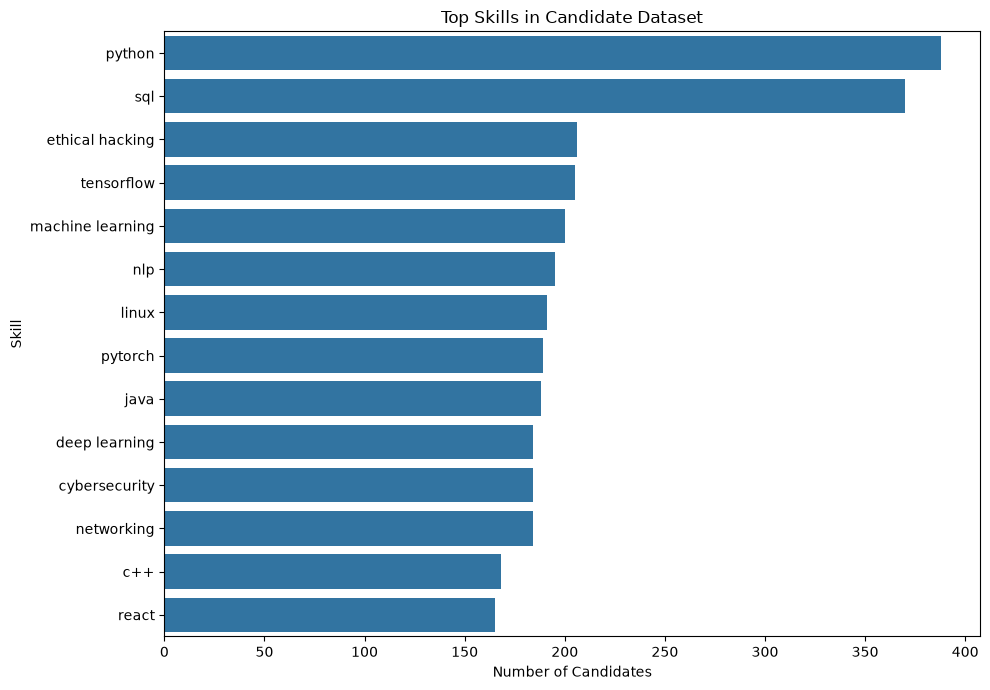

In [128]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=common_skills.head(15),
    x="Candidate_Count",
    y="Skill"
)

plt.title("Top Skills in Candidate Dataset")
plt.xlabel("Number of Candidates")
plt.ylabel("Skill")

plt.tight_layout()
plt.show()

In [130]:
role_skill_profiles = {}

for role in df_clean["Job Role"].dropna().unique():

    role_candidates = df_clean[
        df_clean["Job Role"] == role
    ]

    skill_counter = Counter()

    for skills in role_candidates["Parsed_Skills"]:
        skill_counter.update(skills)

    role_skill_profiles[role] = skill_counter

In [132]:
for role, skills in role_skill_profiles.items():

    print("\n" + "=" * 60)
    print(role)
    print("=" * 60)

    print(
        skills.most_common(10)
    )


AI Researcher
[('tensorflow', 205), ('nlp', 195), ('python', 192), ('pytorch', 189)]

Data Scientist
[('machine learning', 200), ('python', 196), ('sql', 192), ('deep learning', 184)]

Cybersecurity Analyst
[('ethical hacking', 206), ('linux', 191), ('cybersecurity', 184), ('networking', 184)]

Software Engineer
[('java', 188), ('sql', 178), ('c++', 168), ('react', 165)]


In [134]:
ROLE_SKILL_THRESHOLD = 0.20

role_required_skills = {}

for role in df_clean["Job Role"].dropna().unique():

    role_candidates = df_clean[
        df_clean["Job Role"] == role
    ]

    candidate_count = len(role_candidates)

    skill_counter = Counter()

    for skills in role_candidates["Parsed_Skills"]:
        skill_counter.update(skills)

    required = {
        skill
        for skill, count in skill_counter.items()
        if count / candidate_count >= ROLE_SKILL_THRESHOLD
    }

    role_required_skills[role] = required

In [136]:
for role, skills in role_required_skills.items():

    print("\n", role)
    print("Required/common skills:")
    print(sorted(skills))


 AI Researcher
Required/common skills:
['nlp', 'python', 'pytorch', 'tensorflow']

 Data Scientist
Required/common skills:
['deep learning', 'machine learning', 'python', 'sql']

 Cybersecurity Analyst
Required/common skills:
['cybersecurity', 'ethical hacking', 'linux', 'networking']

 Software Engineer
Required/common skills:
['c++', 'java', 'react', 'sql']


In [138]:
def calculate_job_fit(candidate_skills, job_role):

    candidate_skills = set(candidate_skills)

    required_skills = role_required_skills.get(
        job_role,
        set()
    )

    if not required_skills:
        return {
            "matched_skills": set(),
            "missing_skills": set(),
            "job_fit_score": 0.0
        }

    matched_skills = (
        candidate_skills &
        required_skills
    )

    missing_skills = (
        required_skills -
        candidate_skills
    )

    fit_score = (
        len(matched_skills) /
        len(required_skills)
    ) * 100

    return {
        "matched_skills": matched_skills,
        "missing_skills": missing_skills,
        "job_fit_score": fit_score
    }

In [140]:
candidate = df_clean.iloc[0]

result = calculate_job_fit(
    candidate["Parsed_Skills"],
    candidate["Job Role"]
)

print("Candidate:", candidate["Name"])
print("Job Role:", candidate["Job Role"])

print("\nMatched Skills:")
print(sorted(result["matched_skills"]))

print("\nMissing Skills:")
print(sorted(result["missing_skills"]))

print(
    "\nJob Fit Score:",
    round(result["job_fit_score"], 2),
    "%"
)

Candidate: Ashley Ali
Job Role: AI Researcher

Matched Skills:
['nlp', 'pytorch', 'tensorflow']

Missing Skills:
['python']

Job Fit Score: 75.0 %


In [148]:
job_fit_results = []

for _, candidate in df_clean.iterrows():

    result = calculate_job_fit(
        candidate["Parsed_Skills"],
        candidate["Job Role"]
    )

    job_fit_results.append({
        "Resume_ID": candidate["Resume_ID"],
        "Job_Fit_Score": result["job_fit_score"],
        "Matched_Skills": ", ".join(
            sorted(result["matched_skills"])
        ),
        "Missing_Skills": ", ".join(
            sorted(result["missing_skills"])
        )
    })

In [149]:
job_fit_df = pd.DataFrame(
    job_fit_results
)

display(job_fit_df.head())

,Resume_ID,Job_Fit_Score,Matched_Skills,Missing_Skills
0,1,75.0,"nlp, pytorch, tensorflow",python
1,2,100.0,"deep learning, machine learning, python, sql",
2,3,75.0,"cybersecurity, ethical hacking, linux",networking
3,4,75.0,"python, pytorch, tensorflow",nlp
4,5,75.0,"java, react, sql",c++


In [190]:
# ============================================================
# STEP 10 — JOB ROLE MATCHING + SKILL GAP DETECTION
# SELF-CONTAINED VERSION
# ============================================================

import pandas as pd
import numpy as np
from collections import Counter
from pathlib import Path

print("=" * 70)
print("STEP 10 — JOB ROLE MATCHING & SKILL GAP DETECTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Verify required dataset columns
# ------------------------------------------------------------

required_columns = [
    "Resume_ID",
    "Name",
    "Skills",
    "Job Role",
    "Experience (Years)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in df_clean: {missing_columns}"
    )

print("✓ Required dataset columns found")


# ------------------------------------------------------------
# 2. Parse candidate skills
# ------------------------------------------------------------

def parse_skills(value):

    if pd.isna(value):
        return set()

    text = str(value).strip().lower()

    if not text:
        return set()

    # Normalize separators
    text = text.replace(";", ",")
    text = text.replace("|", ",")
    text = text.replace("/", ",")

    # Split and clean
    skills = text.split(",")

    return {
        skill.strip()
        for skill in skills
        if skill.strip()
    }


df_clean["Parsed_Skills"] = (
    df_clean["Skills"]
    .apply(parse_skills)
)

print("✓ Candidate skills parsed")


# ------------------------------------------------------------
# 3. Build role skill profiles
# ------------------------------------------------------------

role_skill_profiles = {}

for role in df_clean["Job Role"].dropna().unique():

    role_candidates = df_clean[
        df_clean["Job Role"] == role
    ]

    skill_counter = Counter()

    for skills in role_candidates["Parsed_Skills"]:
        skill_counter.update(skills)

    role_skill_profiles[role] = skill_counter


print("✓ Role skill profiles created")


# ------------------------------------------------------------
# 4. Determine common/required skills for each role
# ------------------------------------------------------------

ROLE_SKILL_THRESHOLD = 0.20

role_required_skills = {}

for role in df_clean["Job Role"].dropna().unique():

    role_candidates = df_clean[
        df_clean["Job Role"] == role
    ]

    candidate_count = len(role_candidates)

    skill_counter = role_skill_profiles[role]

    required_skills = {
        skill
        for skill, count in skill_counter.items()
        if count / candidate_count >= ROLE_SKILL_THRESHOLD
    }

    role_required_skills[role] = required_skills


print("✓ Role skill requirements created")


# ------------------------------------------------------------
# 5. Display role skill profiles
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ROLE SKILL PROFILES")
print("=" * 70)

for role, skills in role_required_skills.items():

    print(f"\n{role}")
    print("-" * 50)

    if skills:
        print(", ".join(sorted(skills)))
    else:
        print("No common skills found")


# ------------------------------------------------------------
# 6. Job-fit calculation function
# ------------------------------------------------------------

def calculate_job_fit(candidate_skills, job_role):

    candidate_skills = set(candidate_skills)

    required_skills = role_required_skills.get(
        job_role,
        set()
    )

    if not required_skills:

        return {
            "matched_skills": set(),
            "missing_skills": set(),
            "job_fit_score": 0.0
        }

    matched_skills = (
        candidate_skills &
        required_skills
    )

    missing_skills = (
        required_skills -
        candidate_skills
    )

    job_fit_score = (
        len(matched_skills) /
        len(required_skills)
    ) * 100

    return {
        "matched_skills": matched_skills,
        "missing_skills": missing_skills,
        "job_fit_score": job_fit_score
    }


# ------------------------------------------------------------
# 7. Calculate job fit for every candidate
# ------------------------------------------------------------

job_fit_results = []

for _, candidate in df_clean.iterrows():

    result = calculate_job_fit(
        candidate["Parsed_Skills"],
        candidate["Job Role"]
    )

    job_fit_results.append({

        "Resume_ID":
            candidate["Resume_ID"],

        "Job_Fit_Score":
            result["job_fit_score"],

        "Matched_Skills":
            ", ".join(
                sorted(result["matched_skills"])
            ),

        "Missing_Skills":
            ", ".join(
                sorted(result["missing_skills"])
            )
    })


job_fit_df = pd.DataFrame(
    job_fit_results
)

print("\n✓ Job-fit analysis completed")

display(job_fit_df.head())


# ------------------------------------------------------------
# 8. Rebuild ranking_df from df_clean
# ------------------------------------------------------------
#
# IMPORTANT:
# We do NOT depend on the old ranking_df.
#
# If the XGBoost variables exist, use them.
# Otherwise we create the ranking from the existing
# predicted target if available.
# ------------------------------------------------------------

ranking_columns = [
    "Resume_ID",
    "Name",
    "Skills",
    "Experience (Years)",
    "Education",
    "Certifications",
    "Job Role",
    "Salary Expectation ($)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count",
    "AI Score (0-100)"
]

ranking_df = df_clean[ranking_columns].copy()


# ------------------------------------------------------------
# 9. Add model predictions if available
# ------------------------------------------------------------

if "xgb_model" in globals():

    try:

        X_all = df_clean[ML_FEATURES].copy()

        all_predictions = (
            xgb_model.predict(X_all)
        )

        all_probabilities = (
            xgb_model.predict_proba(X_all)[:, 1]
        )

        ranking_df["Hire_Probability"] = (
            all_probabilities * 100
        )

        ranking_df["Predicted_Decision"] = (
            all_predictions
        )

        ranking_df["Predicted_Decision_Label"] = (
            ranking_df["Predicted_Decision"]
            .map({
                0: "Reject",
                1: "Hire"
            })
        )

        print("✓ XGBoost predictions added")

    except Exception as e:

        print(
            "⚠ Could not generate XGBoost predictions:"
        )
        print(e)

else:

    print(
        "⚠ xgb_model not found."
    )

    print(
        "Run the XGBoost training cell before "
        "using model-based ranking."
    )


# ------------------------------------------------------------
# 10. Add job-fit information
# ------------------------------------------------------------

ranking_df = ranking_df.merge(
    job_fit_df,
    on="Resume_ID",
    how="left"
)

print("✓ Job-fit information merged")


# ------------------------------------------------------------
# 11. Candidate strength score
# ------------------------------------------------------------

from sklearn.preprocessing import MinMaxScaler

strength_features = [
    "Experience (Years)",
    "Projects Count",
    "Skill_Count",
    "Certification_Count"
]

strength_scaler = MinMaxScaler()

strength_values = strength_scaler.fit_transform(
    df_clean[strength_features]
)

strength_df = pd.DataFrame(
    strength_values,
    columns=strength_features,
    index=df_clean.index
)

ranking_df["Candidate_Strength_Score"] = (

    strength_df["Experience (Years)"] * 0.35

    +

    strength_df["Projects Count"] * 0.25

    +

    strength_df["Skill_Count"] * 0.25

    +

    strength_df["Certification_Count"] * 0.15

) * 100


# ------------------------------------------------------------
# 12. Recruitment score
# ------------------------------------------------------------

if "Hire_Probability" in ranking_df.columns:

    ranking_df["Recruitment_Score"] = (

        ranking_df["Hire_Probability"] * 0.60

        +

        ranking_df["Job_Fit_Score"] * 0.25

        +

        ranking_df["Candidate_Strength_Score"] * 0.15

    )

else:

    ranking_df["Recruitment_Score"] = (

        ranking_df["Job_Fit_Score"] * 0.60

        +

        ranking_df["Candidate_Strength_Score"] * 0.40

    )


# ------------------------------------------------------------
# 13. Recommendation
# ------------------------------------------------------------

if "Hire_Probability" in ranking_df.columns:

    def recommendation(probability):

        if probability >= 90:
            return "Strong Hire"

        elif probability >= 75:
            return "Hire"

        elif probability >= 50:
            return "Review"

        else:
            return "Reject"


    ranking_df["Recommendation"] = (
        ranking_df["Hire_Probability"]
        .apply(recommendation)
    )

else:

    ranking_df["Recommendation"] = (
        ranking_df["Recruitment_Score"]
        .apply(recommendation)
    )


# ------------------------------------------------------------
# 14. Rank candidates
# ------------------------------------------------------------

ranking_df = (
    ranking_df
    .sort_values(
        "Recruitment_Score",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking_df["Rank"] = (
    ranking_df.index + 1
)


# ------------------------------------------------------------
# 15. Final result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 20 CANDIDATES — JOB FIT + ML RANKING")
print("=" * 70)

display(
    ranking_df[
        [
            "Rank",
            "Name",
            "Job Role",
            "Hire_Probability",
            "Job_Fit_Score",
            "Candidate_Strength_Score",
            "Recruitment_Score",
            "Recommendation"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 16. Skill gap information
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP CANDIDATE SKILL ANALYSIS")
print("=" * 70)

display(
    ranking_df[
        [
            "Rank",
            "Name",
            "Job Role",
            "Job_Fit_Score",
            "Matched_Skills",
            "Missing_Skills"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# 17. Save enhanced ranking
# ------------------------------------------------------------

BASE_DIR = Path.cwd().parent

OUTPUT_DIR = (
    BASE_DIR /
    "data" /
    "processed"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    OUTPUT_DIR /
    "enhanced_candidate_ranking.csv"
)

ranking_df.to_csv(
    output_path,
    index=False
)

print("\n✓ Enhanced ranking saved:")
print(output_path)

print("\n" + "=" * 70)
print("✓ STEP 10 COMPLETE")
print("=" * 70)

STEP 10 — JOB ROLE MATCHING & SKILL GAP DETECTION
✓ Required dataset columns found
✓ Candidate skills parsed
✓ Role skill profiles created
✓ Role skill requirements created

ROLE SKILL PROFILES

AI Researcher
--------------------------------------------------
nlp, python, pytorch, tensorflow

Data Scientist
--------------------------------------------------
deep learning, machine learning, python, sql

Cybersecurity Analyst
--------------------------------------------------
cybersecurity, ethical hacking, linux, networking

Software Engineer
--------------------------------------------------
c++, java, react, sql

✓ Job-fit analysis completed


,Resume_ID,Job_Fit_Score,Matched_Skills,Missing_Skills
0,1,75.0,"nlp, pytorch, tensorflow",python
1,2,100.0,"deep learning, machine learning, python, sql",
2,3,75.0,"cybersecurity, ethical hacking, linux",networking
3,4,75.0,"python, pytorch, tensorflow",nlp
4,5,75.0,"java, react, sql",c++


✓ XGBoost predictions added
✓ Job-fit information merged

TOP 20 CANDIDATES — JOB FIT + ML RANKING


,Rank,Name,Job Role,Hire_Probability,Job_Fit_Score,Candidate_Strength_Score,Recruitment_Score,Recommendation
0,1,Colleen Bates,Software Engineer,99.997162,100.0,100.0,99.998299,Strong Hire
1,2,Carlos Dawson,Cybersecurity Analyst,99.995338,100.0,100.0,99.997204,Strong Hire
2,3,Laurie Wilson,Software Engineer,99.996590,100.0,97.5,99.622955,Strong Hire
3,4,Gerald Greene,Cybersecurity Analyst,99.993813,100.0,97.5,99.621288,Strong Hire
4,5,Timothy Smith,AI Researcher,99.996414,100.0,96.5,99.472852,Strong Hire
5,6,Christine Beck,AI Researcher,99.994919,100.0,96.5,99.471952,Strong Hire
6,7,Traci Austin,Data Scientist,99.995300,100.0,95.0,99.247181,Strong Hire
7,8,John White,Software Engineer,99.997200,100.0,94.0,99.098322,Strong Hire
8,9,Brian Welch,AI Researcher,99.996567,100.0,94.0,99.097944,Strong Hire
9,10,Melissa Preston,Software Engineer,99.996338,100.0,94.0,99.097807,Strong Hire



TOP CANDIDATE SKILL ANALYSIS


,Rank,Name,Job Role,Job_Fit_Score,Matched_Skills,Missing_Skills
0,1,Colleen Bates,Software Engineer,100.0,"c++, java, react, sql",
1,2,Carlos Dawson,Cybersecurity Analyst,100.0,"cybersecurity, ethical hacking, linux, networking",
2,3,Laurie Wilson,Software Engineer,100.0,"c++, java, react, sql",
3,4,Gerald Greene,Cybersecurity Analyst,100.0,"cybersecurity, ethical hacking, linux, networking",
4,5,Timothy Smith,AI Researcher,100.0,"nlp, python, pytorch, tensorflow",
5,6,Christine Beck,AI Researcher,100.0,"nlp, python, pytorch, tensorflow",
6,7,Traci Austin,Data Scientist,100.0,"deep learning, machine learning, python, sql",
7,8,John White,Software Engineer,100.0,"c++, java, react, sql",
8,9,Brian Welch,AI Researcher,100.0,"nlp, python, pytorch, tensorflow",
9,10,Melissa Preston,Software Engineer,100.0,"c++, java, react, sql",



✓ Enhanced ranking saved:
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\enhanced_candidate_ranking.csv

✓ STEP 10 COMPLETE


In [153]:
# ============================================================
# STEP 11 — AI CANDIDATE REPORT GENERATOR
# ============================================================

def generate_candidate_report(resume_id):

    # --------------------------------------------------------
    # Find candidate
    # --------------------------------------------------------

    candidate_rows = ranking_df[
        ranking_df["Resume_ID"] == resume_id
    ]

    if candidate_rows.empty:
        print("❌ Candidate not found.")
        return None

    candidate = candidate_rows.iloc[0]


    # --------------------------------------------------------
    # Basic information
    # --------------------------------------------------------

    name = candidate["Name"]
    role = candidate["Job Role"]


    # --------------------------------------------------------
    # Scores
    # --------------------------------------------------------

    hire_probability = candidate.get(
        "Hire_Probability",
        np.nan
    )

    job_fit = candidate.get(
        "Job_Fit_Score",
        np.nan
    )

    strength_score = candidate.get(
        "Candidate_Strength_Score",
        np.nan
    )

    recruitment_score = candidate.get(
        "Recruitment_Score",
        np.nan
    )

    recommendation = candidate.get(
        "Recommendation",
        "Review"
    )


    # --------------------------------------------------------
    # Skills
    # --------------------------------------------------------

    matched_skills = candidate.get(
        "Matched_Skills",
        ""
    )

    missing_skills = candidate.get(
        "Missing_Skills",
        ""
    )


    # --------------------------------------------------------
    # Print report
    # --------------------------------------------------------

    print("\n")
    print("=" * 70)
    print("                 AI CANDIDATE REPORT")
    print("=" * 70)

    print(f"\nCandidate Name : {name}")
    print(f"Resume ID      : {candidate['Resume_ID']}")
    print(f"Target Role    : {role}")

    print("\n" + "-" * 70)
    print("CANDIDATE SCORES")
    print("-" * 70)

    if not pd.isna(hire_probability):
        print(
            f"Hire Probability       : "
            f"{hire_probability:.2f}%"
        )

    if not pd.isna(job_fit):
        print(
            f"Job Fit Score          : "
            f"{job_fit:.2f}%"
        )

    if not pd.isna(strength_score):
        print(
            f"Candidate Strength     : "
            f"{strength_score:.2f}%"
        )

    if not pd.isna(recruitment_score):
        print(
            f"Recruitment Score      : "
            f"{recruitment_score:.2f}"
        )

    print(
        f"Recommendation          : "
        f"{recommendation}"
    )


    # --------------------------------------------------------
    # Candidate profile
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("CANDIDATE PROFILE")
    print("-" * 70)

    print(
        f"Experience             : "
        f"{candidate['Experience (Years)']} years"
    )

    print(
        f"Projects               : "
        f"{candidate['Projects Count']}"
    )

    print(
        f"Skills Count           : "
        f"{candidate['Skill_Count']}"
    )

    print(
        f"Certifications         : "
        f"{candidate['Certification_Count']}"
    )

    print(
        f"Salary Expectation     : "
        f"${candidate['Salary Expectation ($)']:,.2f}"
    )


    # --------------------------------------------------------
    # Matched skills
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("MATCHED SKILLS")
    print("-" * 70)

    if matched_skills:

        skills = [
            skill.strip()
            for skill in str(matched_skills).split(",")
            if skill.strip()
        ]

        for skill in skills:
            print(f"✓ {skill}")

    else:
        print("No matched skills identified.")


    # --------------------------------------------------------
    # Missing skills
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("SKILL GAPS")
    print("-" * 70)

    if missing_skills:

        skills = [
            skill.strip()
            for skill in str(missing_skills).split(",")
            if skill.strip()
        ]

        for skill in skills:
            print(f"⚠ {skill}")

    else:
        print("No major skill gaps identified.")


    # --------------------------------------------------------
    # Return structured report
    # --------------------------------------------------------

    report = {
        "Resume_ID": candidate["Resume_ID"],
        "Name": name,
        "Job_Role": role,
        "Hire_Probability": hire_probability,
        "Job_Fit_Score": job_fit,
        "Candidate_Strength_Score": strength_score,
        "Recruitment_Score": recruitment_score,
        "Recommendation": recommendation,
        "Matched_Skills": matched_skills,
        "Missing_Skills": missing_skills
    }

    return report

In [155]:
top_resume_id = ranking_df.iloc[0]["Resume_ID"]

report = generate_candidate_report(
    top_resume_id
)



                 AI CANDIDATE REPORT

Candidate Name : Colleen Bates
Resume ID      : 824
Target Role    : Software Engineer

----------------------------------------------------------------------
CANDIDATE SCORES
----------------------------------------------------------------------
Hire Probability       : 100.00%
Job Fit Score          : 100.00%
Candidate Strength     : 100.00%
Recruitment Score      : 100.00
Recommendation          : Strong Hire

----------------------------------------------------------------------
CANDIDATE PROFILE
----------------------------------------------------------------------
Experience             : 10 years
Projects               : 10
Skills Count           : 4
Certifications         : 1
Salary Expectation     : $77,427.00

----------------------------------------------------------------------
MATCHED SKILLS
----------------------------------------------------------------------
✓ c++
✓ java
✓ react
✓ sql

---------------------------------------------

In [157]:
generate_candidate_report(
    ranking_df.iloc[9]["Resume_ID"]
)



                 AI CANDIDATE REPORT

Candidate Name : Melissa Preston
Resume ID      : 753
Target Role    : Software Engineer

----------------------------------------------------------------------
CANDIDATE SCORES
----------------------------------------------------------------------
Hire Probability       : 100.00%
Job Fit Score          : 100.00%
Candidate Strength     : 94.00%
Recruitment Score      : 99.10
Recommendation          : Strong Hire

----------------------------------------------------------------------
CANDIDATE PROFILE
----------------------------------------------------------------------
Experience             : 9 years
Projects               : 9
Skills Count           : 4
Certifications         : 1
Salary Expectation     : $68,203.00

----------------------------------------------------------------------
MATCHED SKILLS
----------------------------------------------------------------------
✓ c++
✓ java
✓ react
✓ sql

-----------------------------------------------

{'Resume_ID': np.int64(753),
 'Name': 'Melissa Preston',
 'Job_Role': 'Software Engineer',
 'Hire_Probability': np.float32(99.99634),
 'Job_Fit_Score': np.float64(100.0),
 'Candidate_Strength_Score': np.float64(94.0),
 'Recruitment_Score': np.float64(99.09780654907226),
 'Recommendation': 'Strong Hire',
 'Matched_Skills': 'c++, java, react, sql',
 'Missing_Skills': ''}

In [158]:
generate_candidate_report(
    ranking_df.iloc[49]["Resume_ID"]
)



                 AI CANDIDATE REPORT

Candidate Name : Scott Kaiser
Resume ID      : 801
Target Role    : AI Researcher

----------------------------------------------------------------------
CANDIDATE SCORES
----------------------------------------------------------------------
Hire Probability       : 99.99%
Job Fit Score          : 100.00%
Candidate Strength     : 83.00%
Recruitment Score      : 97.45
Recommendation          : Strong Hire

----------------------------------------------------------------------
CANDIDATE PROFILE
----------------------------------------------------------------------
Experience             : 8 years
Projects               : 6
Skills Count           : 4
Certifications         : 1
Salary Expectation     : $53,090.00

----------------------------------------------------------------------
MATCHED SKILLS
----------------------------------------------------------------------
✓ nlp
✓ python
✓ pytorch
✓ tensorflow

--------------------------------------------

{'Resume_ID': np.int64(801),
 'Name': 'Scott Kaiser',
 'Job_Role': 'AI Researcher',
 'Hire_Probability': np.float32(99.994865),
 'Job_Fit_Score': np.float64(100.0),
 'Candidate_Strength_Score': np.float64(83.0),
 'Recruitment_Score': np.float64(97.44692153930664),
 'Recommendation': 'Strong Hire',
 'Matched_Skills': 'nlp, python, pytorch, tensorflow',
 'Missing_Skills': ''}

In [160]:
print("explainer:", "explainer" in globals())
print("shap_values:", "shap_values" in globals())
print("feature_names:", "feature_names" in globals())

explainer: False
shap_values: False
feature_names: False


In [162]:
def get_candidate_shap_explanation(resume_id):

    # Find candidate in original test set
    matches = X_test.index[
        df_clean.loc[
            X_test.index,
            "Resume_ID"
        ] == resume_id
    ]

    if len(matches) == 0:
        return None

    original_index = matches[0]

    # Position inside X_test
    candidate_position = list(
        X_test.index
    ).index(original_index)

    candidate_shap = (
        shap_values[candidate_position]
    )

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": candidate_shap
    })

    explanation["Impact"] = (
        explanation["SHAP_Value"].abs()
    )

    explanation = (
        explanation
        .sort_values(
            "Impact",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return explanation

In [165]:
# ============================================================
# STEP 11 — FIXED SHAP CANDIDATE EXPLANATION
# Works for ANY candidate in ranking_df
# ============================================================

def get_candidate_shap_explanation(resume_id):

    # --------------------------------------------------------
    # 1. Find candidate in the complete dataset
    # --------------------------------------------------------

    candidate_rows = df_clean[
        df_clean["Resume_ID"] == resume_id
    ]

    if candidate_rows.empty:
        print(f"❌ Resume_ID not found: {resume_id}")
        return None

    candidate = candidate_rows.iloc[0]


    # --------------------------------------------------------
    # 2. Get the exact ML features used by XGBoost
    # --------------------------------------------------------

    candidate_X = df_clean.loc[
        [candidate.name],
        ML_FEATURES
    ].copy()


    # --------------------------------------------------------
    # 3. Transform candidate using trained preprocessor
    # --------------------------------------------------------

    candidate_transformed = (
        xgb_preprocessor.transform(candidate_X)
    )


    # --------------------------------------------------------
    # 4. Calculate SHAP values
    # --------------------------------------------------------

    candidate_shap = explainer.shap_values(
        candidate_transformed
    )


    # --------------------------------------------------------
    # 5. Handle SHAP output shape
    # --------------------------------------------------------

    candidate_shap = np.asarray(
        candidate_shap
    )

    if candidate_shap.ndim == 2:
        candidate_shap = candidate_shap[0]


    # --------------------------------------------------------
    # 6. Create explanation dataframe
    # --------------------------------------------------------

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": candidate_shap
    })

    explanation["Impact"] = (
        explanation["SHAP_Value"].abs()
    )


    # --------------------------------------------------------
    # 7. Sort by importance
    # --------------------------------------------------------

    explanation = (
        explanation
        .sort_values(
            "Impact",
            ascending=False
        )
        .reset_index(drop=True)
    )


    return explanation

In [167]:
# ============================================================
# SHAP — COMPLETE SETUP AND CANDIDATE EXPLANATION
# ============================================================

import numpy as np
import pandas as pd
import shap

print("=" * 70)
print("SHAP EXPLAINABILITY SETUP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Check that XGBoost model exists
# ------------------------------------------------------------

if "xgb_model" not in globals():

    raise NameError(
        "xgb_model is not defined. "
        "Run the XGBoost training cell first."
    )

print("✓ XGBoost model found")


# ------------------------------------------------------------
# 2. Extract components directly from the pipeline
# ------------------------------------------------------------

xgb_preprocessor = (
    xgb_model.named_steps["preprocessor"]
)

xgb_classifier = (
    xgb_model.named_steps["classifier"]
)

print("✓ XGBoost preprocessor extracted")
print("✓ XGBoost classifier extracted")


# ------------------------------------------------------------
# 3. Get transformed feature names
# ------------------------------------------------------------

feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

print(
    "Number of transformed features:",
    len(feature_names)
)


# ------------------------------------------------------------
# 4. Create SHAP explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_classifier
)

print("✓ SHAP TreeExplainer created")


# ------------------------------------------------------------
# 5. Function to explain ANY candidate
# ------------------------------------------------------------

def get_candidate_shap_explanation(resume_id):

    # Find candidate in complete dataset
    candidate_rows = df_clean[
        df_clean["Resume_ID"] == resume_id
    ]

    if candidate_rows.empty:

        print(
            f"❌ Candidate not found: {resume_id}"
        )

        return None

    candidate = candidate_rows.iloc[0]


    # --------------------------------------------------------
    # Get exactly the features used by XGBoost
    # --------------------------------------------------------

    candidate_X = df_clean.loc[
        [candidate.name],
        ML_FEATURES
    ].copy()


    # --------------------------------------------------------
    # Transform candidate
    # --------------------------------------------------------

    candidate_transformed = (
        xgb_preprocessor.transform(
            candidate_X
        )
    )


    # --------------------------------------------------------
    # Calculate SHAP
    # --------------------------------------------------------

    raw_shap = explainer.shap_values(
        candidate_transformed
    )

    shap_array = np.asarray(
        raw_shap
    )


    # --------------------------------------------------------
    # Handle possible SHAP dimensions
    # --------------------------------------------------------

    if shap_array.ndim == 3:

        # Some SHAP versions return:
        # samples × features × classes

        candidate_shap = (
            shap_array[0, :, 1]
        )

    elif shap_array.ndim == 2:

        candidate_shap = (
            shap_array[0]
        )

    else:

        candidate_shap = (
            shap_array
        )


    # --------------------------------------------------------
    # Make sure dimensions match
    # --------------------------------------------------------

    if len(candidate_shap) != len(feature_names):

        raise ValueError(
            f"SHAP feature mismatch: "
            f"{len(candidate_shap)} SHAP values vs "
            f"{len(feature_names)} feature names."
        )


    # --------------------------------------------------------
    # Create explanation table
    # --------------------------------------------------------

    explanation = pd.DataFrame({

        "Feature":
            feature_names,

        "SHAP_Value":
            candidate_shap

    })

    explanation["Impact"] = (
        explanation["SHAP_Value"].abs()
    )


    # Sort by importance
    explanation = (
        explanation
        .sort_values(
            "Impact",
            ascending=False
        )
        .reset_index(drop=True)
    )


    return explanation


print("✓ SHAP explanation function ready")

c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP EXPLAINABILITY SETUP
✓ XGBoost model found
✓ XGBoost preprocessor extracted
✓ XGBoost classifier extracted
Number of transformed features: 15
✓ SHAP TreeExplainer created
✓ SHAP explanation function ready


In [169]:
top_resume_id = ranking_df.iloc[0]["Resume_ID"]

print("Top candidate Resume ID:")
print(top_resume_id)

shap_explanation = (
    get_candidate_shap_explanation(
        top_resume_id
    )
)

if shap_explanation is not None:

    display(
        shap_explanation.head(10)
    )

Top candidate Resume ID:
824


,Feature,SHAP_Value,Impact
0,num__Experience (Years),2.952828,2.952828
1,num__Project_Experience_Index,2.679410,2.679410
2,num__Projects Count,1.355817,1.355817
3,num__Skill_Count,1.122672,1.122672
4,num__Certification_Count,0.643121,0.643121
5,cat__Job Role_Cybersecurity Analyst,0.137522,0.137522
6,num__Salary Expectation ($),0.125480,0.125480
7,cat__Education_MBA,-0.049573,0.049573
8,cat__Education_B.Sc,0.046361,0.046361
9,cat__Education_PhD,-0.044039,0.044039


In [171]:
# ============================================================
# STEP 11 — FINAL AI CANDIDATE REPORT GENERATOR
# ============================================================

def generate_full_candidate_report(resume_id):

    # --------------------------------------------------------
    # 1. Find candidate
    # --------------------------------------------------------

    candidate_rows = ranking_df[
        ranking_df["Resume_ID"] == resume_id
    ]

    if candidate_rows.empty:
        print("❌ Candidate not found:", resume_id)
        return None

    candidate = candidate_rows.iloc[0]

    # --------------------------------------------------------
    # 2. Basic information
    # --------------------------------------------------------

    name = candidate["Name"]
    role = candidate["Job Role"]

    print("\n")
    print("=" * 75)
    print("                    AI CANDIDATE REPORT")
    print("=" * 75)

    print(f"\nCandidate       : {name}")
    print(f"Resume ID       : {candidate['Resume_ID']}")
    print(f"Job Role        : {role}")

    # --------------------------------------------------------
    # 3. Scores
    # --------------------------------------------------------

    print("\n" + "-" * 75)
    print("AI SCORES")
    print("-" * 75)

    if "Hire_Probability" in candidate.index:
        print(
            f"Hire Probability       : "
            f"{candidate['Hire_Probability']:.2f}%"
        )

    print(
        f"Job Fit Score          : "
        f"{candidate['Job_Fit_Score']:.2f}%"
    )

    print(
        f"Candidate Strength     : "
        f"{candidate['Candidate_Strength_Score']:.2f}%"
    )

    print(
        f"Recruitment Score      : "
        f"{candidate['Recruitment_Score']:.2f}"
    )

    print(
        f"Recommendation         : "
        f"{candidate['Recommendation']}"
    )

    # --------------------------------------------------------
    # 4. Candidate profile
    # --------------------------------------------------------

    print("\n" + "-" * 75)
    print("CANDIDATE PROFILE")
    print("-" * 75)

    print(
        f"Experience             : "
        f"{candidate['Experience (Years)']} years"
    )

    print(
        f"Projects               : "
        f"{candidate['Projects Count']}"
    )

    print(
        f"Skills Count           : "
        f"{candidate['Skill_Count']}"
    )

    print(
        f"Certifications         : "
        f"{candidate['Certification_Count']}"
    )

    print(
        f"Salary Expectation     : "
        f"${candidate['Salary Expectation ($)']:,.2f}"
    )

    # --------------------------------------------------------
    # 5. Matched skills
    # --------------------------------------------------------

    print("\n" + "-" * 75)
    print("MATCHED SKILLS")
    print("-" * 75)

    matched = str(
        candidate["Matched_Skills"]
    )

    if matched and matched.lower() != "nan":

        for skill in matched.split(","):

            skill = skill.strip()

            if skill:
                print(f"✓ {skill}")

    else:
        print("No matched skills identified.")

    # --------------------------------------------------------
    # 6. Missing skills
    # --------------------------------------------------------

    print("\n" + "-" * 75)
    print("SKILL GAPS")
    print("-" * 75)

    missing = str(
        candidate["Missing_Skills"]
    )

    if missing and missing.lower() != "nan":

        for skill in missing.split(","):

            skill = skill.strip()

            if skill:
                print(f"⚠ {skill}")

    else:
        print("No major skill gaps identified.")

    # --------------------------------------------------------
    # 7. SHAP explanation
    # --------------------------------------------------------

    print("\n" + "-" * 75)
    print("MODEL EXPLANATION — SHAP")
    print("-" * 75)

    try:

        shap_explanation = (
            get_candidate_shap_explanation(
                resume_id
            )
        )

    except Exception as e:

        print("⚠ SHAP explanation unavailable.")
        print("Reason:", e)

        shap_explanation = None

    positive_factors = []
    negative_factors = []

    if shap_explanation is not None:

        positive = (
            shap_explanation[
                shap_explanation["SHAP_Value"] > 0
            ]
            .head(5)
        )

        negative = (
            shap_explanation[
                shap_explanation["SHAP_Value"] < 0
            ]
            .sort_values(
                "SHAP_Value"
            )
            .head(5)
        )

        print("\nPositive Model Factors:")

        if positive.empty:
            print("None identified.")

        else:

            for _, row in positive.iterrows():

                print(
                    f"  + {row['Feature']} "
                    f"({row['SHAP_Value']:.4f})"
                )

                positive_factors.append(
                    row["Feature"]
                )

        print("\nNegative Model Factors:")

        if negative.empty:
            print("None identified.")

        else:

            for _, row in negative.iterrows():

                print(
                    f"  - {row['Feature']} "
                    f"({row['SHAP_Value']:.4f})"
                )

                negative_factors.append(
                    row["Feature"]
                )

    # --------------------------------------------------------
    # 8. Structured report
    # --------------------------------------------------------

    report = {

        "Resume_ID":
            candidate["Resume_ID"],

        "Name":
            candidate["Name"],

        "Job_Role":
            candidate["Job Role"],

        "Hire_Probability":
            candidate.get(
                "Hire_Probability",
                np.nan
            ),

        "Job_Fit_Score":
            candidate["Job_Fit_Score"],

        "Candidate_Strength_Score":
            candidate[
                "Candidate_Strength_Score"
            ],

        "Recruitment_Score":
            candidate[
                "Recruitment_Score"
            ],

        "Recommendation":
            candidate[
                "Recommendation"
            ],

        "Matched_Skills":
            candidate[
                "Matched_Skills"
            ],

        "Missing_Skills":
            candidate[
                "Missing_Skills"
            ],

        "Positive_Model_Factors":
            positive_factors,

        "Negative_Model_Factors":
            negative_factors
    }

    return report


print("✓ generate_full_candidate_report() is ready")

✓ generate_full_candidate_report() is ready


In [173]:
top_resume_id = ranking_df.iloc[0]["Resume_ID"]

print("Generating report for:")
print(top_resume_id)

full_report = generate_full_candidate_report(
    top_resume_id
)

Generating report for:
824


                    AI CANDIDATE REPORT

Candidate       : Colleen Bates
Resume ID       : 824
Job Role        : Software Engineer

---------------------------------------------------------------------------
AI SCORES
---------------------------------------------------------------------------
Hire Probability       : 100.00%
Job Fit Score          : 100.00%
Candidate Strength     : 100.00%
Recruitment Score      : 100.00
Recommendation         : Strong Hire

---------------------------------------------------------------------------
CANDIDATE PROFILE
---------------------------------------------------------------------------
Experience             : 10 years
Projects               : 10
Skills Count           : 4
Certifications         : 1
Salary Expectation     : $77,427.00

---------------------------------------------------------------------------
MATCHED SKILLS
---------------------------------------------------------------------------
✓ c++
✓ java
✓ rea

In [175]:
# ============================================================
# STEP 12 — MODEL PACKAGING
# ============================================================

import joblib
from pathlib import Path

print("=" * 70)
print("PACKAGING AI HIRING MODEL")
print("=" * 70)

# Project root
BASE_DIR = Path.cwd().parent

# Create model directory
MODEL_DIR = BASE_DIR / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Model path
MODEL_PATH = MODEL_DIR / "hiring_xgb_model.pkl"

# Save complete pipeline
joblib.dump(
    xgb_model,
    MODEL_PATH
)

print("✓ XGBoost model saved successfully")
print("Model location:")
print(MODEL_PATH)

PACKAGING AI HIRING MODEL
✓ XGBoost model saved successfully
Model location:
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\models\hiring_xgb_model.pkl


In [177]:
print("Model exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    print(
        "Model size:",
        round(
            MODEL_PATH.stat().st_size / 1024,
            2
        ),
        "KB"
    )

Model exists: True
Model size: 330.1 KB


In [179]:
import json

CONFIG_DIR = BASE_DIR / "config"

CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_config = {
    "target": TARGET_COLUMN,
    "features": ML_FEATURES,
    "model_type": "XGBoost",
    "recommendation_thresholds": {
        "strong_hire": 90,
        "hire": 75,
        "review": 50,
        "reject": 0
    }
}

CONFIG_PATH = (
    CONFIG_DIR /
    "model_config.json"
)

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_config,
        f,
        indent=4
    )

print("✓ Model configuration saved")
print(CONFIG_PATH)

✓ Model configuration saved
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\config\model_config.json


In [181]:
import pickle

SKILL_PROFILE_PATH = (
    MODEL_DIR /
    "role_required_skills.pkl"
)

with open(
    SKILL_PROFILE_PATH,
    "wb"
) as f:

    pickle.dump(
        role_required_skills,
        f
    )

print("✓ Role skill profiles saved")
print(SKILL_PROFILE_PATH)

✓ Role skill profiles saved
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\models\role_required_skills.pkl


In [183]:
RANKING_PATH = (
    BASE_DIR /
    "data" /
    "processed" /
    "enhanced_candidate_ranking.csv"
)

RANKING_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

ranking_df.to_csv(
    RANKING_PATH,
    index=False
)

print("✓ Enhanced ranking saved")
print(RANKING_PATH)

✓ Enhanced ranking saved
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\data\processed\enhanced_candidate_ranking.csv


In [185]:
print("\n" + "=" * 70)
print("MODEL PACKAGE VERIFICATION")
print("=" * 70)

files_to_check = {
    "Model": MODEL_PATH,
    "Config": CONFIG_PATH,
    "Role Skill Profiles": SKILL_PROFILE_PATH,
    "Candidate Ranking": RANKING_PATH
}

for name, path in files_to_check.items():

    status = "✓ EXISTS" if path.exists() else "❌ MISSING"

    print(
        f"{name:25} : {status}"
    )

print("=" * 70)


MODEL PACKAGE VERIFICATION
Model                     : ✓ EXISTS
Config                    : ✓ EXISTS
Role Skill Profiles       : ✓ EXISTS
Candidate Ranking         : ✓ EXISTS


In [187]:
loaded_model = joblib.load(
    MODEL_PATH
)

print(
    "Loaded model type:",
    type(loaded_model)
)

Loaded model type: <class 'sklearn.pipeline.Pipeline'>


In [189]:
test_prediction = loaded_model.predict(
    X_all.head(1)
)

test_probability = (
    loaded_model.predict_proba(
        X_all.head(1)
    )[:, 1]
)

print("Test prediction:", test_prediction)
print(
    "Test probability:",
    test_probability
)

Test prediction: [1]
Test probability: [0.99951816]


In [192]:
print("ML FEATURES:")
for i, feature in enumerate(ML_FEATURES, 1):
    print(i, feature)

ML FEATURES:
1 Experience (Years)
2 Salary Expectation ($)
3 Projects Count
4 Skill_Count
5 Certification_Count
6 Project_Experience_Index
7 Education
8 Job Role


In [193]:
print("\nXGBoost pipeline:")
print(xgb_model)


XGBoost pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Experience (Years)',
                                                   'Salary Expectation ($)',
                                                   'Projects Count',
                                                   'Skill_Count',
                                                   'Certification_Count',
                                                   'Project_Experience_Index']),
                                                 ('cat',
                                                 

In [194]:
print("EXACT ML FEATURES:")
for i, feature in enumerate(ML_FEATURES, 1):
    print(i, repr(feature))

print("\nEXACT NUMERICAL FEATURES FROM PREPROCESSOR:")

preprocessor = xgb_model.named_steps["preprocessor"]

for name, transformer, columns in preprocessor.transformers_:
    print(f"\n{name}:")
    print([repr(col) for col in columns])

EXACT ML FEATURES:
1 'Experience (Years)'
2 'Salary Expectation ($)'
3 'Projects Count'
4 'Skill_Count'
5 'Certification_Count'
6 'Project_Experience_Index'
7 'Education'
8 'Job Role'

EXACT NUMERICAL FEATURES FROM PREPROCESSOR:

num:
["'Experience (Years)'", "'Salary Expectation ($)'", "'Projects Count'", "'Skill_Count'", "'Certification_Count'", "'Project_Experience_Index'"]

cat:
["'Education'", "'Job Role'"]


In [196]:
# ============================================================
# STEP 15 — SAVE CANDIDATE STRENGTH SCALER
# ============================================================

import joblib
from pathlib import Path

BASE_DIR = Path.cwd().parent

MODEL_DIR = BASE_DIR / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STRENGTH_SCALER_PATH = (
    MODEL_DIR /
    "candidate_strength_scaler.pkl"
)

joblib.dump(
    strength_scaler,
    STRENGTH_SCALER_PATH
)

print("✓ Candidate strength scaler saved")
print(STRENGTH_SCALER_PATH)

✓ Candidate strength scaler saved
c:\Users\surap\OneDrive\Documents\AI-Hiring-Prediction\models\candidate_strength_scaler.pkl


In [197]:
print(
    "Exists:",
    STRENGTH_SCALER_PATH.exists()
)

Exists: True
